# WESAD Robust Ensemble + Feature Selection + Federated Learning Pipeline

This notebook provides an end-to-end pipeline for the **WESAD stress/emotion dataset**.

**Updated data-loading fix:** the notebook now automatically searches common local paths, extracts any WESAD ZIP files it finds, optionally downloads from Kaggle when credentials are available, and raises a clear setup message only if no WESAD subject pickle files can be found.

Pipeline contents:

1. Download or locate WESAD from Kaggle/local files.
2. Extract labelled windows from physiological signals.
3. Generate statistical, temporal, spectral, and physiology-inspired features.
4. Print every feature with a human-readable description.
5. Inspect signals and extracted features visually.
6. Select the best features using several robust methods.
7. Train strong classical and ensemble classifiers.
8. Save the final labelled dataset, feature list, selected features, scaler, and best model.
9. Run a 10-client federated learning simulation using scikit-learn models.
10. Compare standard FedAvg with a physics-informed FedAvg variant.

No TensorFlow/TinyML code is used in this version.


## 1. Environment setup

Install optional libraries only when needed. The notebook works with core packages: `numpy`, `pandas`, `scikit-learn`, `matplotlib`, `joblib`, and `scipy`.

Optional packages:

- `xgboost` for XGBoost.
- `lightgbm` for LightGBM.
- `shap` for explainability.
- `kaggle` for dataset download.

In [1]:
# Uncomment if needed:
# !pip install kaggle xgboost lightgbm shap scipy joblib

from pathlib import Path
import os
import json
import pickle
import zipfile
import warnings
import math
import random
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import signal, stats
from scipy.signal import find_peaks, welch

from sklearn.model_selection import train_test_split, GroupShuffleSplit, GroupKFold, StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler, RobustScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, balanced_accuracy_score
from sklearn.metrics import roc_auc_score
from sklearn.feature_selection import SelectKBest, mutual_info_classif, f_classif, VarianceThreshold
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC, SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    BaggingClassifier,
    VotingClassifier,
    StackingClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.neural_network import MLPClassifier
from sklearn.base import clone

import joblib

warnings.filterwarnings('ignore')
np.random.seed(42)
random.seed(42)

## 2. Configuration

Set the Kaggle dataset slug if your WESAD Kaggle source differs. Common Kaggle copies use a path similar to `ruchi798/wesad-stress-detection-dataset`, but Kaggle mirrors can change, so update `KAGGLE_DATASET` if necessary.

In [2]:
PROJECT_DIR = Path('/mnt/data/wesad_pipeline') if Path('/mnt/data').exists() else Path('./wesad_pipeline')
RAW_DIR = PROJECT_DIR / 'raw'
PROCESSED_DIR = PROJECT_DIR / 'processed'
MODEL_DIR = PROJECT_DIR / 'models'
FIG_DIR = PROJECT_DIR / 'figures'
FL_DIR = PROJECT_DIR / 'federated'

for d in [RAW_DIR, PROCESSED_DIR, MODEL_DIR, FIG_DIR, FL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Change this if your Kaggle WESAD dataset has another slug.
KAGGLE_DATASET = 'ruchi798/wesad-stress-detection-dataset'

# Optional manual dataset roots. Add your WESAD folder here if it is elsewhere.
# The loader also searches RAW_DIR, PROJECT_DIR, /mnt/data, /kaggle/input, and the current folder.
USER_WESAD_ROOTS = [
    RAW_DIR,
    PROJECT_DIR,
    Path('/mnt/data'),
    Path('/kaggle/input'),
    Path.cwd(),
]

# WESAD labels usually used for classification.
# 0 = undefined/transient, 1 = baseline, 2 = stress, 3 = amusement, 4 = meditation.
LABEL_MAP = {
    1: 'baseline',
    2: 'stress',
    3: 'amusement',
    # 4: 'meditation',  # uncomment for 4-class experiments if available and desired
}

# Chest RespiBAN signals are usually sampled at 700 Hz in WESAD.
CHEST_FS = 700

# Windowing parameters.
WINDOW_SECONDS = 60
OVERLAP = 0.50
TRANSITION_MARGIN_SECONDS = 5

RANDOM_STATE = 42
print('Project directory:', PROJECT_DIR)
print('Raw data directory:', RAW_DIR)


Project directory: wesad_pipeline
Raw data directory: wesad_pipeline\raw


## 3. Download WESAD from Kaggle

Before running this cell, make sure your Kaggle API credentials are configured. Usually this means placing `kaggle.json` in `~/.kaggle/kaggle.json`, or setting the environment variables `KAGGLE_USERNAME` and `KAGGLE_KEY`.

In [3]:
def kaggle_credentials_available():
    kaggle_json = Path.home() / '.kaggle' / 'kaggle.json'
    return kaggle_json.exists() or (os.environ.get('KAGGLE_USERNAME') and os.environ.get('KAGGLE_KEY'))


def extract_zip_safely(zip_path: Path, out_dir: Path):
    """Extract a ZIP file while avoiding accidental path traversal."""
    out_dir.mkdir(parents=True, exist_ok=True)
    print('Extracting:', zip_path)
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        for member in zip_ref.infolist():
            target = (out_dir / member.filename).resolve()
            if not str(target).startswith(str(out_dir.resolve())):
                raise RuntimeError(f'Unsafe zip member blocked: {member.filename}')
        zip_ref.extractall(out_dir)


def download_kaggle_dataset(dataset_slug: str, out_dir: Path, force: bool = False):
    """Download and extract WESAD from Kaggle if credentials are configured."""
    out_dir.mkdir(parents=True, exist_ok=True)
    if (not force) and any(out_dir.rglob('S*.pkl')):
        print('WESAD pickle files already found. Skipping download.')
        return True
    if not kaggle_credentials_available():
        print('Kaggle credentials were not found, so automatic download was skipped.')
        print('Place kaggle.json in ~/.kaggle/ or set KAGGLE_USERNAME and KAGGLE_KEY, then rerun this cell.')
        return False
    cmd = f'kaggle datasets download -d {dataset_slug} -p "{out_dir}" -o'
    print('Running:', cmd)
    status = os.system(cmd)
    if status != 0:
        print('Kaggle download failed. Check KAGGLE_DATASET and Kaggle credentials.')
        return False
    zips = list(out_dir.glob('*.zip'))
    if not zips:
        print('No zip file downloaded from Kaggle.')
        return False
    for z in zips:
        extract_zip_safely(z, out_dir)
    print('Download/extraction complete.')
    return True

# You can run this manually, but the loader cell below can also trigger it automatically when needed.
# download_kaggle_dataset(KAGGLE_DATASET, RAW_DIR)


## 4. Feature description dictionary

This section defines feature descriptions before extraction. After feature extraction, the notebook prints the actual extracted feature names and their descriptions.

In [4]:
def describe_feature(feature_name: str) -> str:
    """Return a readable description for generated WESAD features."""
    parts = feature_name.split('__')
    if len(parts) >= 2:
        sig_name, feat = parts[0], '__'.join(parts[1:])
    else:
        sig_name, feat = 'general', feature_name

    signal_desc = {
        'ECG': 'electrocardiogram signal related to cardiac electrical activity',
        'EDA': 'electrodermal activity signal related to sympathetic arousal and skin conductance',
        'EMG': 'electromyography signal related to muscle activity',
        'RESP': 'respiration signal related to breathing pattern',
        'TEMP': 'skin temperature signal',
        'ACC_x': 'x-axis body acceleration',
        'ACC_y': 'y-axis body acceleration',
        'ACC_z': 'z-axis body acceleration',
        'ACC_mag': 'resultant acceleration magnitude',
    }.get(sig_name, sig_name)

    feat_desc = {
        'mean': 'average value in the window',
        'std': 'standard deviation, measuring variability',
        'median': 'median value, robust central tendency',
        'min': 'minimum value in the window',
        'max': 'maximum value in the window',
        'range': 'maximum minus minimum amplitude',
        'iqr': 'interquartile range, robust spread',
        'mad': 'median absolute deviation, robust variability',
        'rms': 'root mean square signal magnitude',
        'energy': 'average squared signal energy',
        'skew': 'distribution asymmetry',
        'kurtosis': 'distribution peakedness or tail heaviness',
        'slope': 'linear trend across the window',
        'zero_cross_rate': 'rate of sign changes around the mean',
        'peak_count': 'number of detected local peaks',
        'peak_rate': 'detected peaks per second',
        'peak_mean_prominence': 'mean prominence of detected peaks',
        'dominant_freq': 'frequency with the highest spectral power',
        'spectral_entropy': 'entropy of the normalized power spectrum',
        'low_band_power': 'power in the low-frequency band',
        'mid_band_power': 'power in the mid-frequency band',
        'high_band_power': 'power in the high-frequency band',
        'hr_mean': 'estimated mean heart rate from ECG peaks',
        'hr_std': 'variability of estimated heart rate',
        'rr_mean': 'mean interval between successive ECG peaks',
        'rr_std': 'standard deviation of beat-to-beat intervals',
        'rmssd': 'root mean square of successive RR interval differences; short-term HRV',
        'sdnn': 'standard deviation of NN/RR intervals; HRV marker',
        'pnn50': 'percentage of successive RR intervals differing by more than 50 ms',
        'resp_rate': 'estimated breathing rate from respiration peaks',
        'resp_amp': 'respiration amplitude range',
        'eda_peak_rate': 'skin conductance response peak rate',
        'eda_slope': 'trend in skin conductance over the window',
    }.get(feat, 'engineered statistical, temporal, spectral, or physiological descriptor')

    return f'{feat_desc} of {signal_desc}.'

## 5. Load WESAD subject files

The original WESAD pickle files are usually named like `S2.pkl`, `S3.pkl`, etc. This loader handles common Kaggle extraction structures.

In [5]:
def _is_wesad_subject_pickle(path: Path) -> bool:
    """Return True for subject files such as S2.pkl, S3.pkl, ..., S17.pkl."""
    name = path.name
    return name.startswith('S') and name.endswith('.pkl') and name[1:-4].isdigit()


def find_wesad_pickles(search_roots=None):
    """Search multiple common locations for WESAD subject pickle files."""
    if search_roots is None:
        search_roots = USER_WESAD_ROOTS
    files = []
    seen = set()
    for root in search_roots:
        root = Path(root)
        if not root.exists():
            continue
        for p in root.rglob('S*.pkl'):
            if _is_wesad_subject_pickle(p) and p.resolve() not in seen:
                files.append(p)
                seen.add(p.resolve())
    return sorted(files, key=lambda x: (x.parent.as_posix(), x.name))


def extract_existing_wesad_archives(search_roots=None, out_dir: Path = RAW_DIR):
    """Extract likely WESAD ZIP archives found in common notebook locations."""
    if search_roots is None:
        search_roots = USER_WESAD_ROOTS
    extracted = False
    zip_candidates = []
    for root in search_roots:
        root = Path(root)
        if root.exists():
            zip_candidates.extend(root.rglob('*.zip'))
    # Prefer archives whose names mention WESAD/stress, but try all local zips as a fallback.
    zip_candidates = sorted(set(zip_candidates), key=lambda p: ('wesad' not in p.name.lower() and 'stress' not in p.name.lower(), p.name.lower()))
    for z in zip_candidates:
        try:
            before = len(find_wesad_pickles([out_dir]))
            extract_zip_safely(z, out_dir)
            after = len(find_wesad_pickles([out_dir]))
            extracted = extracted or after > before
            if after > 0:
                break
        except zipfile.BadZipFile:
            print('Skipping invalid ZIP:', z)
        except Exception as e:
            print(f'Skipping {z}: {e}')
    return extracted


def prepare_wesad_files(auto_download=True):
    """Locate/extract/download WESAD and return subject pickle paths."""
    pickle_files = find_wesad_pickles()
    if pickle_files:
        return pickle_files

    print("No S*.pkl files found yet. Searching for local ZIP archives to extract...")
    extract_existing_wesad_archives()
    pickle_files = find_wesad_pickles()
    if pickle_files:
        return pickle_files

    if auto_download:
        print("No local WESAD archive found. Trying Kaggle download if credentials are available...")
        download_kaggle_dataset(KAGGLE_DATASET, RAW_DIR)
        pickle_files = find_wesad_pickles()
        if pickle_files:
            return pickle_files

    searched = "\n".join(f"  - {Path(r)}" for r in USER_WESAD_ROOTS)
    message = f"""No WESAD subject pickle files were found.

Expected files like S2.pkl, S3.pkl, ..., S17.pkl.

Fix options:
1) Put the extracted WESAD folder or ZIP file under RAW_DIR shown above, then rerun this cell.
2) Configure Kaggle credentials and rerun the Kaggle download cell.
3) Add your local WESAD path to USER_WESAD_ROOTS in the configuration cell.

Searched these roots:
{searched}
"""
    raise FileNotFoundError(message)

def load_subject_pickle(path: Path):
    with open(path, 'rb') as f:
        data = pickle.load(f, encoding='latin1')
    return data


def get_subject_id(path: Path):
    return path.stem

pickle_files = prepare_wesad_files(auto_download=True)
print('Found WESAD pickle files:', len(pickle_files))
for p in pickle_files[:10]:
    print(' ', p)


Found WESAD pickle files: 30
  C:\Users\ayan\OneDrive - NILU\Desktop\debug\personal\wesad_robust_ml_project\raw\WESAD\S10\S10.pkl
  C:\Users\ayan\OneDrive - NILU\Desktop\debug\personal\wesad_robust_ml_project\raw\WESAD\S11\S11.pkl
  C:\Users\ayan\OneDrive - NILU\Desktop\debug\personal\wesad_robust_ml_project\raw\WESAD\S13\S13.pkl
  C:\Users\ayan\OneDrive - NILU\Desktop\debug\personal\wesad_robust_ml_project\raw\WESAD\S14\S14.pkl
  C:\Users\ayan\OneDrive - NILU\Desktop\debug\personal\wesad_robust_ml_project\raw\WESAD\S15\S15.pkl
  C:\Users\ayan\OneDrive - NILU\Desktop\debug\personal\wesad_robust_ml_project\raw\WESAD\S16\S16.pkl
  C:\Users\ayan\OneDrive - NILU\Desktop\debug\personal\wesad_robust_ml_project\raw\WESAD\S17\S17.pkl
  C:\Users\ayan\OneDrive - NILU\Desktop\debug\personal\wesad_robust_ml_project\raw\WESAD\S2\S2.pkl
  C:\Users\ayan\OneDrive - NILU\Desktop\debug\personal\wesad_robust_ml_project\raw\WESAD\S3\S3.pkl
  C:\Users\ayan\OneDrive - NILU\Desktop\debug\personal\wesad_robus

## 6. Signal utilities and robust feature extraction

The feature extractor uses compact, interpretable features that work well with classical ML models and are suitable for later federated learning.

In [6]:
def safe_1d(x):
    arr = np.asarray(x)
    if arr.ndim > 1:
        arr = arr.squeeze()
    return arr.astype(float)


def clean_signal(x):
    x = safe_1d(x)
    x = np.nan_to_num(x, nan=np.nanmedian(x) if np.isfinite(x).any() else 0.0, posinf=0.0, neginf=0.0)
    return x


def linear_slope(x):
    x = clean_signal(x)
    if len(x) < 3:
        return 0.0
    t = np.arange(len(x))
    return float(np.polyfit(t, x, 1)[0])


def spectral_features(x, fs, prefix):
    x = clean_signal(x)
    feats = {}
    if len(x) < max(32, int(fs)):
        feats[f'{prefix}__dominant_freq'] = 0.0
        feats[f'{prefix}__spectral_entropy'] = 0.0
        feats[f'{prefix}__low_band_power'] = 0.0
        feats[f'{prefix}__mid_band_power'] = 0.0
        feats[f'{prefix}__high_band_power'] = 0.0
        return feats
    nperseg = min(len(x), int(fs * 4))
    freqs, power = welch(x, fs=fs, nperseg=nperseg)
    power = np.nan_to_num(power, nan=0.0)
    if power.sum() <= 0:
        norm_power = np.ones_like(power) / max(len(power), 1)
    else:
        norm_power = power / power.sum()
    feats[f'{prefix}__dominant_freq'] = float(freqs[np.argmax(power)]) if len(freqs) else 0.0
    feats[f'{prefix}__spectral_entropy'] = float(stats.entropy(norm_power)) if len(norm_power) else 0.0
    bands = {
        'low_band_power': (0.01, 0.10),
        'mid_band_power': (0.10, 0.50),
        'high_band_power': (0.50, min(5.0, fs / 2)),
    }
    for name, (lo, hi) in bands.items():
        mask = (freqs >= lo) & (freqs < hi)
        feats[f'{prefix}__{name}'] = float(np.trapz(power[mask], freqs[mask])) if mask.any() else 0.0
    return feats


def basic_features(x, fs, prefix):
    x = clean_signal(x)
    xc = x - np.nanmean(x)
    feats = {
        f'{prefix}__mean': float(np.mean(x)),
        f'{prefix}__std': float(np.std(x)),
        f'{prefix}__median': float(np.median(x)),
        f'{prefix}__min': float(np.min(x)),
        f'{prefix}__max': float(np.max(x)),
        f'{prefix}__range': float(np.max(x) - np.min(x)),
        f'{prefix}__iqr': float(np.percentile(x, 75) - np.percentile(x, 25)),
        f'{prefix}__mad': float(np.median(np.abs(x - np.median(x)))),
        f'{prefix}__rms': float(np.sqrt(np.mean(x ** 2))),
        f'{prefix}__energy': float(np.mean(x ** 2)),
        f'{prefix}__skew': float(stats.skew(x)) if len(x) > 3 and np.std(x) > 0 else 0.0,
        f'{prefix}__kurtosis': float(stats.kurtosis(x)) if len(x) > 3 and np.std(x) > 0 else 0.0,
        f'{prefix}__slope': linear_slope(x),
        f'{prefix}__zero_cross_rate': float(np.mean(np.diff(np.signbit(xc)) != 0)) if len(x) > 2 else 0.0,
    }
    distance = max(1, int(fs * 0.3))
    peaks, props = find_peaks(x, distance=distance, prominence=np.std(x) * 0.25 if np.std(x) > 0 else None)
    feats[f'{prefix}__peak_count'] = int(len(peaks))
    feats[f'{prefix}__peak_rate'] = float(len(peaks) / (len(x) / fs)) if len(x) > 0 else 0.0
    feats[f'{prefix}__peak_mean_prominence'] = float(np.mean(props.get('prominences', [0]))) if len(peaks) else 0.0
    feats.update(spectral_features(x, fs, prefix))
    return feats


def ecg_hrv_features(ecg, fs=CHEST_FS):
    ecg = clean_signal(ecg)
    feats = {}
    if len(ecg) < fs * 5:
        return {f'ECG__{k}': 0.0 for k in ['hr_mean','hr_std','rr_mean','rr_std','rmssd','sdnn','pnn50']}
    x = (ecg - np.mean(ecg)) / (np.std(ecg) + 1e-8)
    peaks, _ = find_peaks(x, distance=int(0.3 * fs), prominence=0.5)
    rr = np.diff(peaks) / fs
    rr = rr[(rr > 0.3) & (rr < 2.0)]
    if len(rr) < 2:
        vals = dict(hr_mean=0, hr_std=0, rr_mean=0, rr_std=0, rmssd=0, sdnn=0, pnn50=0)
    else:
        hr = 60.0 / rr
        diff_rr = np.diff(rr)
        vals = {
            'hr_mean': np.mean(hr),
            'hr_std': np.std(hr),
            'rr_mean': np.mean(rr),
            'rr_std': np.std(rr),
            'rmssd': np.sqrt(np.mean(diff_rr ** 2)) if len(diff_rr) else 0,
            'sdnn': np.std(rr),
            'pnn50': np.mean(np.abs(diff_rr) > 0.05) if len(diff_rr) else 0,
        }
    return {f'ECG__{k}': float(v) for k, v in vals.items()}


def resp_physiology_features(resp, fs=CHEST_FS):
    resp = clean_signal(resp)
    x = signal.detrend(resp) if len(resp) > 2 else resp
    peaks, _ = find_peaks(x, distance=int(1.0 * fs), prominence=np.std(x) * 0.2 if np.std(x) > 0 else None)
    duration_min = len(x) / fs / 60 if len(x) else 0
    return {
        'RESP__resp_rate': float(len(peaks) / duration_min) if duration_min > 0 else 0.0,
        'RESP__resp_amp': float(np.percentile(x, 95) - np.percentile(x, 5)) if len(x) else 0.0,
    }


def eda_physiology_features(eda, fs=CHEST_FS):
    eda = clean_signal(eda)
    # Low-pass smooth for slow skin conductance response.
    if len(eda) > fs:
        b, a = signal.butter(2, min(1.0 / (fs / 2), 0.99), btype='low')
        try:
            sm = signal.filtfilt(b, a, eda)
        except Exception:
            sm = eda
    else:
        sm = eda
    peaks, _ = find_peaks(sm, distance=int(1.0 * fs), prominence=np.std(sm) * 0.1 if np.std(sm) > 0 else None)
    duration_min = len(sm) / fs / 60 if len(sm) else 0
    return {
        'EDA__eda_peak_rate': float(len(peaks) / duration_min) if duration_min > 0 else 0.0,
        'EDA__eda_slope': linear_slope(sm),
    }


def extract_window_features(signals_dict, start, end, fs=CHEST_FS):
    feats = {}
    # Chest signals in WESAD usually include ACC, ECG, EDA, EMG, RESP, TEMP.
    for sig_name in ['ECG', 'EDA', 'EMG', 'RESP', 'TEMP']:
        if sig_name in signals_dict:
            x = clean_signal(signals_dict[sig_name][start:end])
            feats.update(basic_features(x, fs, sig_name))
    if 'ACC' in signals_dict:
        acc = np.asarray(signals_dict['ACC'])[start:end]
        if acc.ndim == 2 and acc.shape[1] >= 3:
            for i, ax in enumerate(['x', 'y', 'z']):
                feats.update(basic_features(acc[:, i], fs, f'ACC_{ax}'))
            mag = np.sqrt(np.sum(acc[:, :3] ** 2, axis=1))
            feats.update(basic_features(mag, fs, 'ACC_mag'))
    if 'ECG' in signals_dict:
        feats.update(ecg_hrv_features(signals_dict['ECG'][start:end], fs))
    if 'RESP' in signals_dict:
        feats.update(resp_physiology_features(signals_dict['RESP'][start:end], fs))
    if 'EDA' in signals_dict:
        feats.update(eda_physiology_features(signals_dict['EDA'][start:end], fs))
    return feats

## 7. Build labelled feature dataset

This cell extracts windows and assigns each window the majority label. Undefined labels and transition regions are removed to reduce boundary noise.

In [7]:
def remove_transition_indices(labels, fs, margin_seconds=5):
    labels = np.asarray(labels).reshape(-1)
    valid = np.ones(len(labels), dtype=bool)
    changes = np.where(np.diff(labels) != 0)[0]
    margin = int(margin_seconds * fs)
    for c in changes:
        lo = max(0, c - margin)
        hi = min(len(labels), c + margin + 1)
        valid[lo:hi] = False
    return valid


def build_feature_dataset(pickle_files, label_map=LABEL_MAP, fs=CHEST_FS, window_seconds=WINDOW_SECONDS, overlap=OVERLAP):
    rows = []
    window_size = int(window_seconds * fs)
    step = int(window_size * (1 - overlap))
    if step <= 0:
        raise ValueError('Overlap too high; step size must be positive.')

    for p in pickle_files:
        subject = get_subject_id(p)
        print('Processing', subject)
        data = load_subject_pickle(p)
        chest = data['signal']['chest']
        labels = np.asarray(data['label']).reshape(-1)
        valid_mask = remove_transition_indices(labels, fs, TRANSITION_MARGIN_SECONDS)
        n = len(labels)
        for start in range(0, n - window_size + 1, step):
            end = start + window_size
            window_labels = labels[start:end]
            window_valid = valid_mask[start:end]
            if window_valid.mean() < 0.95:
                continue
            counts = Counter(window_labels.tolist())
            label_id, label_count = counts.most_common(1)[0]
            if label_id not in label_map:
                continue
            if label_count / len(window_labels) < 0.90:
                continue
            feats = extract_window_features(chest, start, end, fs)
            feats['subject'] = subject
            feats['label_id'] = int(label_id)
            feats['label'] = label_map[int(label_id)]
            feats['start_sample'] = int(start)
            feats['end_sample'] = int(end)
            rows.append(feats)
    df = pd.DataFrame(rows)
    return df

feature_csv = PROCESSED_DIR / 'wesad_features_labelled.csv'
if feature_csv.exists():
    df = pd.read_csv(feature_csv)
    print('Loaded existing feature dataset:', df.shape)
else:
    # Re-check here so this cell still works even if the notebook was restarted
    # or if the user extracted/downloaded WESAD after running the loader cell.
    pickle_files = prepare_wesad_files(auto_download=True)
    df = build_feature_dataset(pickle_files)
    df.to_csv(feature_csv, index=False)
    print('Saved:', feature_csv)

print(df.shape)
display(df.head())
print(df['label'].value_counts())
print('Subjects:', sorted(df['subject'].unique()))

Loaded existing feature dataset: (2026, 168)
(2026, 168)


,ECG__mean,ECG__std,ECG__median,ECG__min,ECG__max,ECG__range,ECG__iqr,ECG__mad,ECG__rms,ECG__energy,...,ECG__rmssd,ECG__sdnn,ECG__pnn50,EDA__eda_peak_rate,EDA__eda_slope,subject,label_id,label,start_sample,end_sample
0,0.001372,0.151259,0.020828,-0.667923,0.838211,1.506134,0.125427,0.059555,0.151265,0.022881,...,0.050530,0.053111,0.021505,31.0,2.392958e-07,S10,1,baseline,84000,126000
1,0.000920,0.159931,0.003525,-0.664948,0.871902,1.536850,0.146084,0.079926,0.159933,0.025579,...,0.008353,0.023697,0.000000,34.0,8.542949e-08,S10,1,baseline,105000,147000
2,0.001438,0.159889,-0.000847,-0.700928,0.871902,1.572830,0.145260,0.083290,0.159896,0.025567,...,0.014966,0.024055,0.010000,34.0,1.008302e-07,S10,1,baseline,126000,168000
3,0.001176,0.160889,-0.003891,-0.700928,0.827225,1.528152,0.147675,0.087158,0.160893,0.025887,...,0.006801,0.017488,0.000000,36.0,1.374814e-07,S10,1,baseline,147000,189000
4,0.001172,0.162042,0.004990,-0.620316,0.971970,1.592285,0.148132,0.079468,0.162046,0.026259,...,0.056948,0.061882,0.118812,36.0,1.670954e-07,S10,1,baseline,168000,210000


label
baseline     1114
stress        602
amusement     310
Name: count, dtype: int64
Subjects: ['S10', 'S11', 'S13', 'S14', 'S15', 'S16', 'S17', 'S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9']


## 8. Print all extracted features and descriptions

This cell creates a publication-friendly feature dictionary. It also saves the dictionary as CSV.

In [8]:
metadata_cols = ['subject', 'label_id', 'label', 'start_sample', 'end_sample']
feature_names = [c for c in df.columns if c not in metadata_cols]

feature_description_df = pd.DataFrame({
    'feature': feature_names,
    'description': [describe_feature(f) for f in feature_names]
}).sort_values('feature').reset_index(drop=True)

pd.set_option('display.max_rows', 300)
display(feature_description_df)
feature_description_path = PROCESSED_DIR / 'feature_descriptions.csv'
feature_description_df.to_csv(feature_description_path, index=False)
print('Number of features:', len(feature_names))
print('Saved feature descriptions to:', feature_description_path)

,feature,description
0,ACC_mag__dominant_freq,frequency with the highest spectral power of r...
1,ACC_mag__energy,average squared signal energy of resultant acc...
2,ACC_mag__high_band_power,power in the high-frequency band of resultant ...
3,ACC_mag__iqr,"interquartile range, robust spread of resultan..."
4,ACC_mag__kurtosis,distribution peakedness or tail heaviness of r...
5,ACC_mag__low_band_power,power in the low-frequency band of resultant a...
6,ACC_mag__mad,"median absolute deviation, robust variability ..."
7,ACC_mag__max,maximum value in the window of resultant accel...
8,ACC_mag__mean,average value in the window of resultant accel...
9,ACC_mag__median,"median value, robust central tendency of resul..."


Number of features: 163
Saved feature descriptions to: wesad_pipeline\processed\feature_descriptions.csv


## 9. Data inspection and visualization

These plots help inspect label balance, subject distribution, feature distributions, correlation, and possible domain/subject shift.

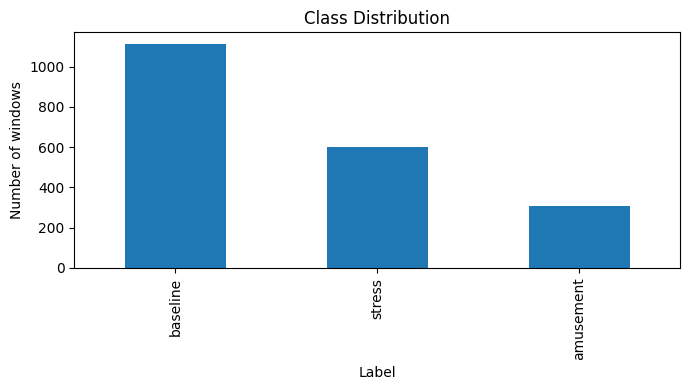

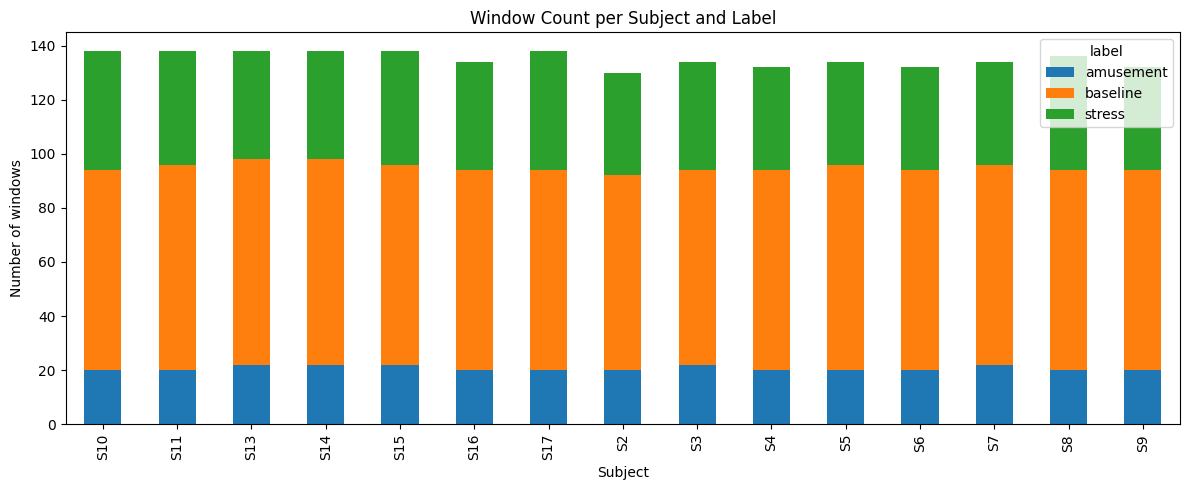

Top missing-value rates:


,missing_rate
ECG__mean,0.0
ECG__std,0.0
ECG__median,0.0
ECG__min,0.0
ECG__max,0.0
ECG__range,0.0
ECG__iqr,0.0
ECG__mad,0.0
ECG__rms,0.0
ECG__energy,0.0


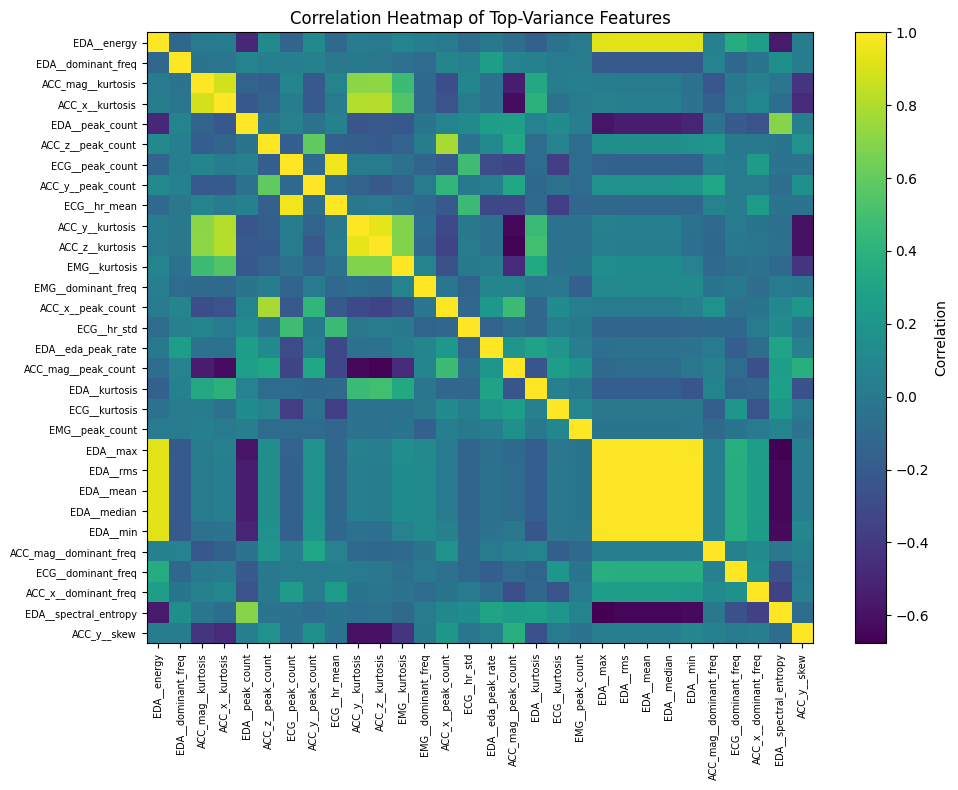

In [9]:
# Label distribution
plt.figure(figsize=(7,4))
df['label'].value_counts().plot(kind='bar')
plt.title('Class Distribution')
plt.xlabel('Label')
plt.ylabel('Number of windows')
plt.savefig("Class.png", dpi=300, bbox_inches="tight")
plt.tight_layout()
plt.show()

# Subject distribution by label
subject_label_counts = pd.crosstab(df['subject'], df['label'])
subject_label_counts.plot(kind='bar', stacked=True, figsize=(12,5))
plt.savefig("windows.png", dpi=300, bbox_inches="tight")
plt.title('Window Count per Subject and Label')
plt.xlabel('Subject')
plt.ylabel('Number of windows')
plt.tight_layout()
plt.show()

# Missing value rate
missing = df[feature_names].isna().mean().sort_values(ascending=False)
print('Top missing-value rates:')
display(missing.head(20).to_frame('missing_rate'))

# Feature correlation for top variance features
numeric_df = df[feature_names].replace([np.inf, -np.inf], np.nan)
var_rank = numeric_df.var(numeric_only=True).sort_values(ascending=False).head(30).index
corr = numeric_df[var_rank].corr()
plt.figure(figsize=(10,8))
plt.imshow(corr, aspect='auto')
plt.colorbar(label='Correlation')
plt.xticks(range(len(var_rank)), var_rank, rotation=90, fontsize=7)
plt.yticks(range(len(var_rank)), var_rank, fontsize=7)
plt.savefig("Correlation Heatmap.png", dpi=300, bbox_inches="tight")
plt.title('Correlation Heatmap of Top-Variance Features')
plt.tight_layout()
plt.show()

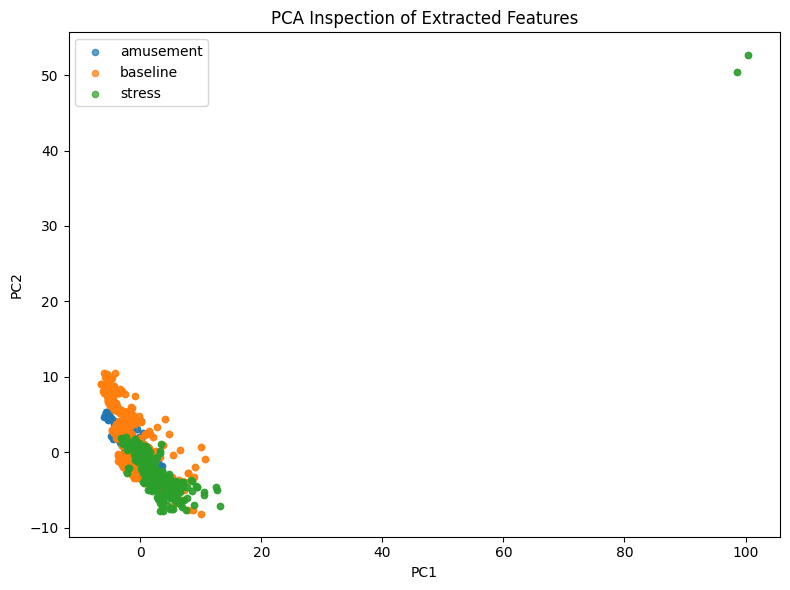

In [10]:
# t-SNE/PCA feature visualization using selected raw features before feature selection.
from sklearn.decomposition import PCA

X_vis = df[feature_names].replace([np.inf, -np.inf], np.nan)
X_vis = pd.DataFrame(SimpleImputer(strategy='median').fit_transform(X_vis), columns=feature_names)
X_vis_scaled = StandardScaler().fit_transform(X_vis)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
emb = pca.fit_transform(X_vis_scaled)
plot_df = pd.DataFrame({'pc1': emb[:,0], 'pc2': emb[:,1], 'label': df['label'], 'subject': df['subject']})

plt.figure(figsize=(8,6))
for lab in sorted(plot_df['label'].unique()):
    sub = plot_df[plot_df['label'] == lab]
    plt.scatter(sub['pc1'], sub['pc2'], label=lab, alpha=0.7, s=20)
plt.title('PCA Inspection of Extracted Features')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.tight_layout()
plt.show()

## 10. Train/test split

The default is **subject-independent** evaluation using `GroupShuffleSplit`. This is stricter and more realistic than random window splitting because the same participant does not appear in both training and testing sets.

In [11]:
X = df[feature_names].replace([np.inf, -np.inf], np.nan)
y_text = df['label'].copy()
groups = df['subject'].copy()

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)
class_names = label_encoder.classes_.tolist()

splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train_raw, X_test_raw = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y[train_idx], y[test_idx]
groups_train, groups_test = groups.iloc[train_idx].copy(), groups.iloc[test_idx].copy()

print('Train:', X_train_raw.shape, 'Test:', X_test_raw.shape)
print('Train subjects:', sorted(groups_train.unique()))
print('Test subjects:', sorted(groups_test.unique()))
print('Classes:', class_names)

Train: (1488, 163) Test: (538, 163)
Train subjects: ['S11', 'S13', 'S14', 'S15', 'S16', 'S17', 'S2', 'S3', 'S5', 'S7', 'S9']
Test subjects: ['S10', 'S4', 'S6', 'S8']
Classes: ['amusement', 'baseline', 'stress']


## 11. Robust preprocessing

Use median imputation and robust scaling. Tree ensembles do not strictly require scaling, but scaling is important for SVM, logistic regression, MLP, and the federated SGD models.

In [12]:
preprocess = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler()),
])

X_train_pre = pd.DataFrame(preprocess.fit_transform(X_train_raw), columns=feature_names, index=X_train_raw.index)
X_test_pre = pd.DataFrame(preprocess.transform(X_test_raw), columns=feature_names, index=X_test_raw.index)

joblib.dump(preprocess, MODEL_DIR / 'preprocess_imputer_robust_scaler.joblib')
joblib.dump(label_encoder, MODEL_DIR / 'label_encoder.joblib')
print('Preprocessed shapes:', X_train_pre.shape, X_test_pre.shape)

Preprocessed shapes: (1488, 163) (538, 163)


## 12. Best feature selection cell

This section combines several complementary feature-selection signals:

- Variance filtering to remove almost-constant features.
- Mutual information with the class label.
- ANOVA F-score.
- Extra Trees impurity importance.
- Permutation importance from a validation split.
- Correlation pruning to reduce redundancy.

The final selected feature set is saved and printed with descriptions.

In [13]:
def rank_to_score(values, higher_is_better=True):
    s = pd.Series(values).replace([np.inf, -np.inf], np.nan).fillna(0)
    if not higher_is_better:
        s = -s
    ranks = s.rank(method='average', ascending=True)
    return ranks / ranks.max()

# Remove near-constant features.
vt = VarianceThreshold(threshold=1e-8)
vt.fit(X_train_pre)
non_constant_features = X_train_pre.columns[vt.get_support()].tolist()
X_train_fs_base = X_train_pre[non_constant_features]
X_test_fs_base = X_test_pre[non_constant_features]

# Mutual information and ANOVA.
mi = mutual_info_classif(X_train_fs_base, y_train, random_state=RANDOM_STATE)
f_scores, f_pvals = f_classif(X_train_fs_base, y_train)

# Extra Trees importance.
et_selector = ExtraTreesClassifier(
    n_estimators=600,
    max_depth=None,
    min_samples_leaf=2,
    max_features='sqrt',
    class_weight='balanced',
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
et_selector.fit(X_train_fs_base, y_train)
et_imp = et_selector.feature_importances_

# Permutation importance on a validation split inside training subjects.
X_fs_tr, X_fs_val, y_fs_tr, y_fs_val = train_test_split(
    X_train_fs_base, y_train, test_size=0.25, random_state=RANDOM_STATE, stratify=y_train
)
perm_model = ExtraTreesClassifier(
    n_estimators=400,
    min_samples_leaf=2,
    max_features='sqrt',
    class_weight='balanced',
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
perm_model.fit(X_fs_tr, y_fs_tr)
perm = permutation_importance(
    perm_model, X_fs_val, y_fs_val, n_repeats=8, random_state=RANDOM_STATE, n_jobs=-1, scoring='f1_macro'
)
perm_imp = perm.importances_mean

ranking_df = pd.DataFrame({
    'feature': non_constant_features,
    'description': [describe_feature(f) for f in non_constant_features],
    'mutual_info': mi,
    'anova_f': np.nan_to_num(f_scores, nan=0.0, posinf=0.0, neginf=0.0),
    'extra_trees_importance': et_imp,
    'permutation_importance': perm_imp,
})
ranking_df['combined_score'] = (
    rank_to_score(ranking_df['mutual_info']) +
    rank_to_score(ranking_df['anova_f']) +
    rank_to_score(ranking_df['extra_trees_importance']) +
    rank_to_score(ranking_df['permutation_importance'])
) / 4
ranking_df = ranking_df.sort_values('combined_score', ascending=False).reset_index(drop=True)

display(ranking_df.head(50))
ranking_df.to_csv(PROCESSED_DIR / 'feature_selection_ranking.csv', index=False)
print('Saved feature ranking:', PROCESSED_DIR / 'feature_selection_ranking.csv')

,feature,description,mutual_info,anova_f,extra_trees_importance,permutation_importance,combined_score
0,ACC_x__peak_mean_prominence,mean prominence of detected peaks of x-axis bo...,0.591449,776.722046,0.021991,0.0,0.964765
1,ACC_mag__mad,"median absolute deviation, robust variability ...",0.547763,633.139789,0.025958,0.0,0.947987
2,ECG__rr_mean,mean interval between successive ECG peaks of ...,0.559783,558.140843,0.020382,0.0,0.942953
3,ACC_mag__zero_cross_rate,rate of sign changes around the mean of result...,0.528207,446.395916,0.026766,0.0,0.936242
4,ECG__hr_mean,estimated mean heart rate from ECG peaks of el...,0.518574,667.029117,0.021083,0.0,0.934564
5,EDA__spectral_entropy,entropy of the normalized power spectrum of el...,0.496697,504.529844,0.030842,0.0,0.926174
6,ACC_mag__iqr,"interquartile range, robust spread of resultan...",0.518618,436.928077,0.019175,0.0,0.921141
7,ACC_z__peak_mean_prominence,mean prominence of detected peaks of z-axis bo...,0.537326,403.093640,0.014288,0.0,0.917785
8,ECG__energy,average squared signal energy of electrocardio...,0.571425,170.178307,0.011990,0.0,0.906879
9,ECG__kurtosis,distribution peakedness or tail heaviness of e...,0.495203,265.688680,0.018116,0.0,0.901007


Saved feature ranking: wesad_pipeline\processed\feature_selection_ranking.csv


In [14]:
def correlation_prune(feature_rank_df, X_data, max_features=40, corr_threshold=0.92):
    selected = []
    corr_abs = X_data[feature_rank_df['feature'].tolist()].corr().abs()
    for f in feature_rank_df['feature']:
        if len(selected) >= max_features:
            break
        if not selected:
            selected.append(f)
            continue
        max_corr = corr_abs.loc[f, selected].max()
        if pd.isna(max_corr) or max_corr < corr_threshold:
            selected.append(f)
    return selected

MAX_SELECTED_FEATURES = min(40, max(10, int(0.35 * len(non_constant_features))))
selected_features = correlation_prune(ranking_df, X_train_fs_base, max_features=MAX_SELECTED_FEATURES, corr_threshold=0.92)

selected_feature_df = ranking_df[ranking_df['feature'].isin(selected_features)].copy()
selected_feature_df['selected_order'] = selected_feature_df['feature'].apply(lambda f: selected_features.index(f) + 1)
selected_feature_df = selected_feature_df.sort_values('selected_order')

display(selected_feature_df[['selected_order','feature','description','combined_score','mutual_info','extra_trees_importance','permutation_importance']])

with open(PROCESSED_DIR / 'selected_features.json', 'w') as f:
    json.dump(selected_features, f, indent=2)
selected_feature_df.to_csv(PROCESSED_DIR / 'selected_features_with_descriptions.csv', index=False)

print('Selected feature count:', len(selected_features))
print('Selected features:')
for i, f in enumerate(selected_features, 1):
    print(f'{i:02d}. {f} -- {describe_feature(f)}')

X_train_sel = X_train_pre[selected_features]
X_test_sel = X_test_pre[selected_features]

,selected_order,feature,description,combined_score,mutual_info,extra_trees_importance,permutation_importance
0,1,ACC_x__peak_mean_prominence,mean prominence of detected peaks of x-axis bo...,0.964765,0.591449,0.021991,0.0
1,2,ACC_mag__mad,"median absolute deviation, robust variability ...",0.947987,0.547763,0.025958,0.0
2,3,ECG__rr_mean,mean interval between successive ECG peaks of ...,0.942953,0.559783,0.020382,0.0
3,4,ACC_mag__zero_cross_rate,rate of sign changes around the mean of result...,0.936242,0.528207,0.026766,0.0
5,5,EDA__spectral_entropy,entropy of the normalized power spectrum of el...,0.926174,0.496697,0.030842,0.0
7,6,ACC_z__peak_mean_prominence,mean prominence of detected peaks of z-axis bo...,0.917785,0.537326,0.014288,0.0
8,7,ECG__energy,average squared signal energy of electrocardio...,0.906879,0.571425,0.011990,0.0
9,8,ECG__kurtosis,distribution peakedness or tail heaviness of e...,0.901007,0.495203,0.018116,0.0
11,9,ECG__skew,distribution asymmetry of electrocardiogram si...,0.885906,0.509395,0.014909,0.0
12,10,EDA__max,maximum value in the window of electrodermal a...,0.879195,0.717076,0.009267,0.0


Selected feature count: 40
Selected features:
01. ACC_x__peak_mean_prominence -- mean prominence of detected peaks of x-axis body acceleration.
02. ACC_mag__mad -- median absolute deviation, robust variability of resultant acceleration magnitude.
03. ECG__rr_mean -- mean interval between successive ECG peaks of electrocardiogram signal related to cardiac electrical activity.
04. ACC_mag__zero_cross_rate -- rate of sign changes around the mean of resultant acceleration magnitude.
05. EDA__spectral_entropy -- entropy of the normalized power spectrum of electrodermal activity signal related to sympathetic arousal and skin conductance.
06. ACC_z__peak_mean_prominence -- mean prominence of detected peaks of z-axis body acceleration.
07. ECG__energy -- average squared signal energy of electrocardiogram signal related to cardiac electrical activity.
08. ECG__kurtosis -- distribution peakedness or tail heaviness of electrocardiogram signal related to cardiac electrical activity.
09. ECG__skew 

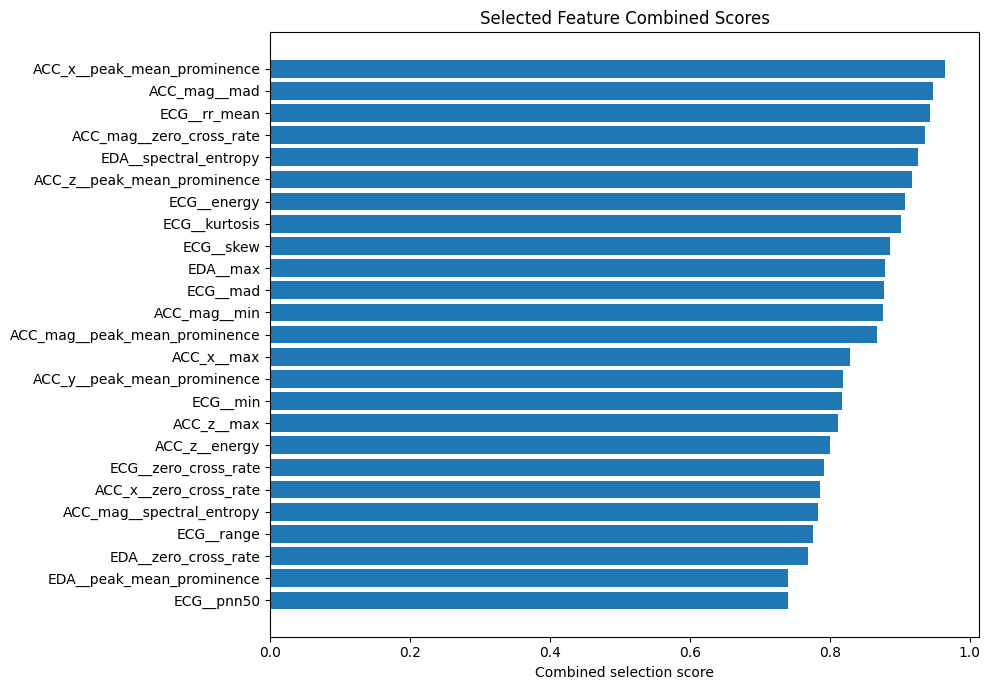

In [15]:
# Plot top selected feature scores.
plot_top = selected_feature_df.sort_values('combined_score', ascending=True).tail(25)
plt.figure(figsize=(10, max(5, len(plot_top) * 0.28)))
plt.barh(plot_top['feature'], plot_top['combined_score'])
plt.title('Selected Feature Combined Scores')
plt.xlabel('Combined selection score')
plt.tight_layout()
plt.savefig("Selected Feature.png", dpi=300, bbox_inches="tight")
plt.show()

## 13. Save final labelled classification dataset

This file contains only selected features, subject IDs, and labels. It is the recommended input for classical ML and federated experiments.

In [16]:
final_df = pd.concat([
    df[['subject', 'label', 'label_id', 'start_sample', 'end_sample']].reset_index(drop=True),
    pd.DataFrame(preprocess.transform(X), columns=feature_names)[selected_features].reset_index(drop=True)
], axis=1)

final_csv = PROCESSED_DIR / 'wesad_selected_features_for_classification.csv'
final_df.to_csv(final_csv, index=False)
print('Saved final labelled dataset:', final_csv)
display(final_df.head())

Saved final labelled dataset: wesad_pipeline\processed\wesad_selected_features_for_classification.csv


,subject,label,label_id,start_sample,end_sample,ACC_x__peak_mean_prominence,ACC_mag__mad,ECG__rr_mean,ACC_mag__zero_cross_rate,EDA__spectral_entropy,...,EMG__zero_cross_rate,EMG__mean,EMG__std,ACC_z__min,EMG__dominant_freq,ACC_mag__peak_count,ACC_x__mad,ACC_y__zero_cross_rate,ACC_z__zero_cross_rate,EMG__range
0,S10,baseline,1,84000,126000,-0.122607,0.378918,-0.820458,-0.507815,0.178993,...,0.387642,1.009810,-0.415935,0.208474,-0.180147,-0.222222,2.095226,-0.710282,-0.884831,-0.582054
1,S10,baseline,1,105000,147000,-0.280818,-0.208112,-0.926483,0.267757,0.181976,...,1.004371,0.995375,-0.484326,0.208474,-0.356618,-0.555556,-0.047627,0.672425,0.008279,-0.628539
2,S10,baseline,1,126000,168000,-0.405588,-0.235882,-1.031033,0.316824,0.158256,...,1.158951,0.980834,-0.481552,0.271466,-0.158088,-1.222222,-0.333362,0.235413,0.639883,-0.578110
3,S10,baseline,1,147000,189000,-0.365634,-0.231136,-1.088067,0.318407,0.145190,...,0.855752,1.007196,-0.474883,0.245969,-0.312500,-1.777778,-0.380960,0.621336,0.804967,-0.580082
4,S10,baseline,1,168000,210000,-0.178624,-0.182436,-1.057493,0.210776,0.165299,...,0.498510,0.987815,-0.454902,0.220472,-0.136029,-1.555556,-0.476186,-0.606634,0.396883,-0.545429


## 14. Robust and ensemble model training

This section trains strong classical models. Optional XGBoost and LightGBM are included automatically if installed.

In [17]:
def get_model_zoo():
    models = {
        'logistic_regression_balanced': LogisticRegression(max_iter=2000, class_weight='balanced', C=1.0, solver='saga', n_jobs=-1, random_state=RANDOM_STATE),
        'linear_svc_balanced': LinearSVC(class_weight='balanced', C=0.5, random_state=RANDOM_STATE),
        'rbf_svc_balanced': SVC(C=3.0, gamma='scale', class_weight='balanced', probability=True, random_state=RANDOM_STATE),
        'random_forest_robust': RandomForestClassifier(n_estimators=500, max_depth=None, min_samples_leaf=2, max_features='sqrt', class_weight='balanced_subsample', random_state=RANDOM_STATE, n_jobs=-1),
        'extra_trees_robust': ExtraTreesClassifier(n_estimators=700, max_depth=None, min_samples_leaf=2, max_features='sqrt', class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
        'bagging_trees': BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=None, min_samples_leaf=3, class_weight='balanced', random_state=RANDOM_STATE), n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1),
        'gradient_boosting': GradientBoostingClassifier(random_state=RANDOM_STATE),
        'hist_gradient_boosting': HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, l2_regularization=0.05, random_state=RANDOM_STATE),
        'adaboost': AdaBoostClassifier(n_estimators=300, learning_rate=0.05, random_state=RANDOM_STATE),
        'mlp_sklearn_robust': MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', alpha=1e-3, learning_rate_init=1e-3, max_iter=500, early_stopping=True, random_state=RANDOM_STATE),
        'knn_distance': KNeighborsClassifier(n_neighbors=7, weights='distance'),
    }
    try:
        from xgboost import XGBClassifier
        models['xgboost_optional'] = XGBClassifier(
            n_estimators=400,
            max_depth=4,
            learning_rate=0.04,
            subsample=0.85,
            colsample_bytree=0.85,
            objective='multi:softprob',
            eval_metric='mlogloss',
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
    except Exception as e:
        print('XGBoost not available:', e)
    try:
        from lightgbm import LGBMClassifier
        models['lightgbm_optional'] = LGBMClassifier(
            n_estimators=500,
            learning_rate=0.04,
            num_leaves=31,
            subsample=0.85,
            colsample_bytree=0.85,
            class_weight='balanced',
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbose=-1,
        )
    except Exception as e:
        print('LightGBM not available:', e)
    return models

models = get_model_zoo()
print('Models:', list(models.keys()))

LightGBM not available: No module named 'lightgbm'
Models: ['logistic_regression_balanced', 'linear_svc_balanced', 'rbf_svc_balanced', 'random_forest_robust', 'extra_trees_robust', 'bagging_trees', 'gradient_boosting', 'hist_gradient_boosting', 'adaboost', 'mlp_sklearn_robust', 'knn_distance', 'xgboost_optional']


In [18]:
def evaluate_model(name, model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    row = {
        'model': name,
        'accuracy': accuracy_score(y_test, pred),
        'balanced_accuracy': balanced_accuracy_score(y_test, pred),
        'macro_f1': f1_score(y_test, pred, average='macro'),
        'weighted_f1': f1_score(y_test, pred, average='weighted'),
    }
    return row, pred, model

results = []
fitted_models = {}
predictions = {}

for name, model in models.items():
    print('Training:', name)
    try:
        row, pred, fitted = evaluate_model(name, clone(model), X_train_sel, y_train, X_test_sel, y_test)
        results.append(row)
        fitted_models[name] = fitted
        predictions[name] = pred
    except Exception as e:
        print('Failed:', name, e)

results_df = pd.DataFrame(results).sort_values('macro_f1', ascending=False).reset_index(drop=True)
display(results_df)
results_df.to_csv(PROCESSED_DIR / 'robust_model_results.csv', index=False)

Training: logistic_regression_balanced
Training: linear_svc_balanced
Training: rbf_svc_balanced
Training: random_forest_robust
Training: extra_trees_robust
Training: bagging_trees
Training: gradient_boosting
Training: hist_gradient_boosting
Training: adaboost
Training: mlp_sklearn_robust
Training: knn_distance
Training: xgboost_optional


,model,accuracy,balanced_accuracy,macro_f1,weighted_f1
0,logistic_regression_balanced,0.843866,0.762307,0.773321,0.835337
1,rbf_svc_balanced,0.802974,0.727725,0.728696,0.799734
2,linear_svc_balanced,0.773234,0.681657,0.682670,0.762462
3,knn_distance,0.784387,0.648693,0.659717,0.765715
4,gradient_boosting,0.817844,0.660914,0.641900,0.774683
5,adaboost,0.828996,0.663452,0.633022,0.774443
6,xgboost_optional,0.825279,0.651885,0.630988,0.772081
7,hist_gradient_boosting,0.817844,0.643655,0.623732,0.764880
8,extra_trees_robust,0.836431,0.650206,0.615091,0.772477
9,random_forest_robust,0.814126,0.633458,0.609387,0.756333


## 15. Voting, stacking, and hyperparameter tuning

In [19]:
# Build ensembles from the strongest available base learners.
base_names = [n for n in ['extra_trees_robust', 'random_forest_robust', 'hist_gradient_boosting', 'rbf_svc_balanced', 'xgboost_optional', 'lightgbm_optional'] if n in fitted_models]
base_estimators = [(n, clone(models[n])) for n in base_names]
print('Base models for meta-ensembles:', base_names)

ensemble_results = []

if len(base_estimators) >= 3:
    voting = VotingClassifier(estimators=base_estimators, voting='soft', n_jobs=-1)
    try:
        row, pred, voting_fit = evaluate_model('soft_voting_ensemble', voting, X_train_sel, y_train, X_test_sel, y_test)
        ensemble_results.append(row)
        fitted_models['soft_voting_ensemble'] = voting_fit
        predictions['soft_voting_ensemble'] = pred
    except Exception as e:
        print('Soft voting failed, trying hard voting:', e)
        voting = VotingClassifier(estimators=base_estimators, voting='hard', n_jobs=-1)
        row, pred, voting_fit = evaluate_model('hard_voting_ensemble', voting, X_train_sel, y_train, X_test_sel, y_test)
        ensemble_results.append(row)
        fitted_models['hard_voting_ensemble'] = voting_fit
        predictions['hard_voting_ensemble'] = pred

if len(base_estimators) >= 3:
    stack = StackingClassifier(
        estimators=base_estimators,
        final_estimator=LogisticRegression(max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE),
        cv=3,
        n_jobs=-1,
        passthrough=False,
    )
    try:
        row, pred, stack_fit = evaluate_model('stacking_ensemble', stack, X_train_sel, y_train, X_test_sel, y_test)
        ensemble_results.append(row)
        fitted_models['stacking_ensemble'] = stack_fit
        predictions['stacking_ensemble'] = pred
    except Exception as e:
        print('Stacking failed:', e)

# Randomized search for Extra Trees.
param_dist = {
    'n_estimators': [400, 700, 1000],
    'max_depth': [None, 8, 12, 18, 25],
    'min_samples_leaf': [1, 2, 3, 5],
    'max_features': ['sqrt', 'log2', 0.4, 0.6, 0.8],
    'class_weight': ['balanced', 'balanced_subsample'],
}
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
search = RandomizedSearchCV(
    ExtraTreesClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=20,
    scoring='f1_macro',
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1,
)
search.fit(X_train_sel, y_train)
print('Best ExtraTrees params:', search.best_params_)
row, pred, tuned_fit = evaluate_model('extra_trees_tuned', search.best_estimator_, X_train_sel, y_train, X_test_sel, y_test)
ensemble_results.append(row)
fitted_models['extra_trees_tuned'] = tuned_fit
predictions['extra_trees_tuned'] = pred

en_results_df = pd.DataFrame(ensemble_results)
all_results_df = pd.concat([results_df, en_results_df], ignore_index=True).sort_values('macro_f1', ascending=False).reset_index(drop=True)
display(all_results_df)
all_results_df.to_csv(PROCESSED_DIR / 'all_model_results.csv', index=False)

Base models for meta-ensembles: ['extra_trees_robust', 'random_forest_robust', 'hist_gradient_boosting', 'rbf_svc_balanced', 'xgboost_optional']
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best ExtraTrees params: {'n_estimators': 700, 'min_samples_leaf': 1, 'max_features': 0.4, 'max_depth': 25, 'class_weight': 'balanced_subsample'}


,model,accuracy,balanced_accuracy,macro_f1,weighted_f1
0,logistic_regression_balanced,0.843866,0.762307,0.773321,0.835337
1,rbf_svc_balanced,0.802974,0.727725,0.728696,0.799734
2,linear_svc_balanced,0.773234,0.681657,0.682670,0.762462
3,knn_distance,0.784387,0.648693,0.659717,0.765715
4,gradient_boosting,0.817844,0.660914,0.641900,0.774683
5,soft_voting_ensemble,0.836431,0.660505,0.640212,0.782742
6,stacking_ensemble,0.836431,0.660505,0.640212,0.782742
7,adaboost,0.828996,0.663452,0.633022,0.774443
8,xgboost_optional,0.825279,0.651885,0.630988,0.772081
9,hist_gradient_boosting,0.817844,0.643655,0.623732,0.764880


## 16. Best model report and saving

Best model: logistic_regression_balanced
              precision    recall  f1-score   support

   amusement       0.67      0.45      0.54        80
    baseline       0.86      0.90      0.88       296
      stress       0.87      0.94      0.90       162

    accuracy                           0.84       538
   macro avg       0.80      0.76      0.77       538
weighted avg       0.83      0.84      0.84       538



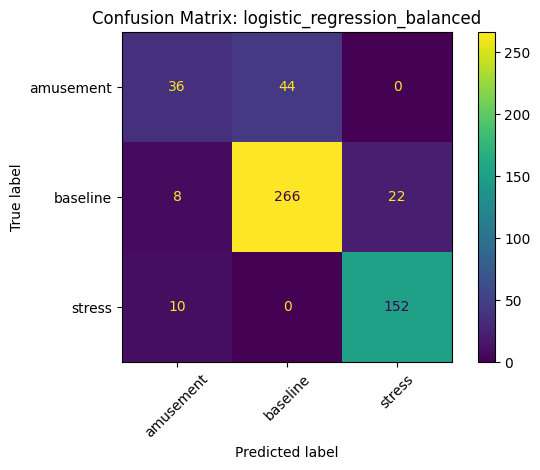

Saved best model artifact: wesad_pipeline\models\best_robust_ensemble_model.joblib


In [20]:
best_name = all_results_df.iloc[0]['model']
best_model = fitted_models[best_name]
best_pred = predictions[best_name]

print('Best model:', best_name)
print(classification_report(y_test, best_pred, target_names=class_names))

cm = confusion_matrix(y_test, best_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(xticks_rotation=45)
plt.title(f'Confusion Matrix: {best_name}')
plt.tight_layout()
plt.savefig("ConfusionMatrixDisplay.png", dpi=300, bbox_inches="tight")
plt.show()

artifact = {
    'model_name': best_name,
    'model': best_model,
    'selected_features': selected_features,
    'feature_descriptions': selected_feature_df,
    'preprocess': preprocess,
    'label_encoder': label_encoder,
    'class_names': class_names,
    'results': all_results_df,
}
model_path = MODEL_DIR / 'best_robust_ensemble_model.joblib'
joblib.dump(artifact, model_path)
print('Saved best model artifact:', model_path)

## 17. Optional SHAP explainability

Run this if `shap` is installed. For tree-based models it gives useful global feature interpretation.

In [21]:
try:
    import shap
    if any(k in best_name for k in ['tree', 'forest', 'xgboost', 'lightgbm']):
        explainer = shap.Explainer(best_model, X_train_sel)
        shap_values = explainer(X_test_sel)
        shap.summary_plot(shap_values, X_test_sel, show=True)
    else:
        print('SHAP skipped: best model is not a supported tree model for this quick explainer.')
except Exception as e:
    print('SHAP skipped:', e)

SHAP skipped: Numba needs NumPy 2.1 or less. Got NumPy 2.2.


# Federated learning simulation over 10 clients

The following cells implement federated learning using scikit-learn only. Each client holds a local subset of the selected-feature dataset. The server trains a global linear classifier using federated averaging of model parameters.

Compared methods:

1. **Standard FedAvg**: weights each client update by client sample size.
2. **Loss-aware FedAvg**: reduces the influence of clients with high local loss.
3. **Physics-informed FedAvg**: weights updates using sample size plus a physiological signal-quality score.

### Physics-informed FedAvg idea

Physiological stress signals obey useful assumptions:

- EDA, ECG/HRV, RESP, TEMP, and ACC features should remain finite and physiologically stable.
- Extremely noisy client data, heavy motion artifacts, very high feature drift, or severe class imbalance can produce unreliable updates.
- A client with cleaner, more stable physiological features should contribute slightly more to the global model.

The physics-informed score below combines:

- **Completeness**: lower missing/imputed feature burden.
- **Physiological stability**: lower robust z-score outlier rate on selected physiological features.
- **Class balance**: higher label entropy.
- **Domain closeness**: lower MMD-like distance between client feature distribution and global feature distribution.

This is a novel, lightweight physics-inspired version of FedAvg for wearable physiological stress classification.

## 18. Create 10 federated clients

Subjects are distributed across 10 clients. If fewer than 10 subjects are available after filtering, the code splits windows into 10 stratified groups as a fallback.

In [22]:
# Prepare full selected-feature data for FL.
X_all = final_df[selected_features].copy().reset_index(drop=True)
y_all = label_encoder.transform(final_df['label']).astype(int)
subjects_all = final_df['subject'].astype(str).reset_index(drop=True)

# Hold out some subjects for global testing, using the same test subjects as above when possible.
test_subjects = set(groups_test.astype(str).unique())
train_mask_fl = ~subjects_all.isin(test_subjects)
test_mask_fl = subjects_all.isin(test_subjects)

X_fl_train = X_all.loc[train_mask_fl].reset_index(drop=True)
y_fl_train = y_all[train_mask_fl.values]
subjects_fl_train = subjects_all.loc[train_mask_fl].reset_index(drop=True)

X_fl_test = X_all.loc[test_mask_fl].reset_index(drop=True)
y_fl_test = y_all[test_mask_fl.values]
subjects_fl_test = subjects_all.loc[test_mask_fl].reset_index(drop=True)

print('FL train:', X_fl_train.shape, 'FL test:', X_fl_test.shape)
print('FL train subjects:', sorted(subjects_fl_train.unique()))
print('FL test subjects:', sorted(subjects_fl_test.unique()))


def make_10_clients(X_df, y_arr, subjects, n_clients=10, random_state=RANDOM_STATE):
    rng = np.random.default_rng(random_state)
    clients = []
    unique_subjects = np.array(sorted(pd.Series(subjects).unique()))
    if len(unique_subjects) >= n_clients:
        rng.shuffle(unique_subjects)
        subject_groups = np.array_split(unique_subjects, n_clients)
        for cid, sg in enumerate(subject_groups):
            idx = np.where(pd.Series(subjects).isin(sg).values)[0]
            clients.append({'client_id': cid, 'subjects': list(sg), 'indices': idx})
    else:
        # Fallback: stratified random split of samples.
        skf = StratifiedKFold(n_splits=n_clients, shuffle=True, random_state=random_state)
        dummy = np.zeros(len(y_arr))
        for cid, (_, idx) in enumerate(skf.split(dummy, y_arr)):
            clients.append({'client_id': cid, 'subjects': sorted(pd.Series(subjects.iloc[idx]).unique()), 'indices': idx})
    return clients

clients = make_10_clients(X_fl_train, y_fl_train, subjects_fl_train, n_clients=10)
client_summary = []
for c in clients:
    idx = c['indices']
    labs = Counter(y_fl_train[idx])
    client_summary.append({
        'client_id': c['client_id'],
        'n_samples': len(idx),
        'subjects': ','.join(map(str, c['subjects'])),
        **{f'class_{class_names[k]}': labs.get(k, 0) for k in range(len(class_names))}
    })
client_summary_df = pd.DataFrame(client_summary)
display(client_summary_df)
client_summary_df.to_csv(FL_DIR / 'client_summary.csv', index=False)

FL train: (1488, 40) FL test: (538, 40)
FL train subjects: ['S11', 'S13', 'S14', 'S15', 'S16', 'S17', 'S2', 'S3', 'S5', 'S7', 'S9']
FL test subjects: ['S10', 'S4', 'S6', 'S8']


,client_id,n_samples,subjects,class_amusement,class_baseline,class_stress
0,0,264,"S2,S3",42,144,78
1,1,138,S11,20,76,42
2,2,132,S9,20,74,38
3,3,138,S15,22,74,42
4,4,138,S17,20,74,44
5,5,138,S14,22,76,40
6,6,134,S16,20,74,40
7,7,134,S7,22,74,38
8,8,138,S13,22,76,40
9,9,134,S5,20,76,38


## 19. Federated linear model utilities

The model is a multinomial logistic classifier trained locally with `SGDClassifier`. Its coefficients are averaged on the server.

In [23]:
def new_sgd_model(alpha=1e-4, learning_rate='optimal', eta0=0.01):
    return SGDClassifier(
        loss='log_loss',
        penalty='l2',
        alpha=alpha,
        learning_rate=learning_rate,
        eta0=eta0,
        max_iter=1,
        tol=None,
        random_state=RANDOM_STATE,
        warm_start=True,
    )


def initialize_model(n_features, classes, alpha=1e-4, eta0=0.01):
    model = new_sgd_model(alpha=alpha, eta0=eta0)
    # Partial fit on one small dummy batch to initialize coef_ and intercept_.
    X_dummy = np.zeros((len(classes), n_features))
    y_dummy = np.array(classes)
    model.partial_fit(X_dummy, y_dummy, classes=np.array(classes))
    model.coef_[:] = 0.0
    model.intercept_[:] = 0.0
    return model


def get_params(model):
    return model.coef_.copy(), model.intercept_.copy()


def set_params(model, coef, intercept):
    model.coef_ = coef.copy()
    model.intercept_ = intercept.copy()
    return model


def local_train_from_global(global_coef, global_intercept, X_local, y_local, classes, local_epochs=2, alpha=1e-4, eta0=0.01, batch_size=64):
    model = initialize_model(X_local.shape[1], classes, alpha=alpha, eta0=eta0)
    set_params(model, global_coef, global_intercept)
    n = len(y_local)
    rng = np.random.default_rng(RANDOM_STATE)
    for _ in range(local_epochs):
        order = rng.permutation(n)
        for start in range(0, n, batch_size):
            batch_idx = order[start:start+batch_size]
            model.partial_fit(X_local[batch_idx], y_local[batch_idx], classes=np.array(classes))
    pred_prob = model.predict_proba(X_local)
    eps = 1e-12
    local_loss = -np.mean(np.log(pred_prob[np.arange(n), y_local] + eps))
    return get_params(model), local_loss


def predict_from_params(coef, intercept, X):
    logits = X @ coef.T + intercept
    return np.argmax(logits, axis=1)


def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    ez = np.exp(z)
    return ez / ez.sum(axis=1, keepdims=True)


def evaluate_params(coef, intercept, X, y):
    pred = predict_from_params(coef, intercept, X)
    return {
        'accuracy': accuracy_score(y, pred),
        'balanced_accuracy': balanced_accuracy_score(y, pred),
        'macro_f1': f1_score(y, pred, average='macro'),
        'weighted_f1': f1_score(y, pred, average='weighted'),
    }

## 20. Physics-informed client weighting

The following cell computes the physiological reliability score used by physics-informed FedAvg.

In [24]:
def normalized_entropy(y_local, n_classes):
    counts = np.bincount(y_local, minlength=n_classes).astype(float)
    p = counts / max(counts.sum(), 1)
    p = p[p > 0]
    if len(p) <= 1:
        return 0.0
    return float(stats.entropy(p) / np.log(n_classes))


def rbf_mmd_approx(X_client, X_global, max_samples=300, gamma=None, random_state=RANDOM_STATE):
    rng = np.random.default_rng(random_state)
    Xc = np.asarray(X_client)
    Xg = np.asarray(X_global)
    if len(Xc) > max_samples:
        Xc = Xc[rng.choice(len(Xc), max_samples, replace=False)]
    if len(Xg) > max_samples:
        Xg = Xg[rng.choice(len(Xg), max_samples, replace=False)]
    if gamma is None:
        gamma = 1.0 / max(Xg.shape[1], 1)
    def kernel_mean(A, B):
        # Efficient enough for small sampled matrices.
        d2 = ((A[:, None, :] - B[None, :, :]) ** 2).sum(axis=2)
        return np.exp(-gamma * d2).mean()
    return float(kernel_mean(Xc, Xc) + kernel_mean(Xg, Xg) - 2 * kernel_mean(Xc, Xg))


def physiology_score(X_client_df, y_client, X_global_df, selected_features, n_classes):
    # 1. Completeness score.
    missing_rate = float(pd.DataFrame(X_client_df).isna().mean().mean())
    completeness = 1.0 - min(max(missing_rate, 0.0), 1.0)

    # 2. Physiological stability using robust z-scores.
    Xc = pd.DataFrame(X_client_df, columns=selected_features).replace([np.inf, -np.inf], np.nan).fillna(0)
    med = X_global_df[selected_features].median()
    iqr = X_global_df[selected_features].quantile(0.75) - X_global_df[selected_features].quantile(0.25)
    rz = (Xc[selected_features] - med) / (iqr.replace(0, np.nan).fillna(1.0) + 1e-8)
    outlier_rate = float((rz.abs() > 6.0).mean().mean())
    stability = float(np.exp(-outlier_rate))

    # 3. Label entropy/client class balance.
    balance = normalized_entropy(y_client, n_classes)

    # 4. Domain closeness using MMD-like distance.
    mmd = rbf_mmd_approx(Xc[selected_features].values, X_global_df[selected_features].values)
    domain_closeness = float(np.exp(-mmd))

    # Physics-informed reliability score.
    score = 0.30 * completeness + 0.30 * stability + 0.20 * balance + 0.20 * domain_closeness
    return {
        'physics_score': float(score),
        'completeness': completeness,
        'stability': stability,
        'balance': balance,
        'domain_closeness': domain_closeness,
        'mmd': mmd,
        'outlier_rate': outlier_rate,
    }

client_quality_rows = []
for c in clients:
    idx = c['indices']
    q = physiology_score(X_fl_train.iloc[idx], y_fl_train[idx], X_fl_train, selected_features, len(class_names))
    client_quality_rows.append({'client_id': c['client_id'], 'n_samples': len(idx), **q})
client_quality_df = pd.DataFrame(client_quality_rows)
display(client_quality_df)
client_quality_df.to_csv(FL_DIR / 'client_physics_quality_scores.csv', index=False)

,client_id,n_samples,physics_score,completeness,stability,balance,domain_closeness,mmd,outlier_rate
0,0,264,0.955895,1.0,0.992829,0.895041,0.895192,0.110717,0.007197
1,1,138,0.952297,1.0,1.000000,0.883384,0.878099,0.129996,0.000000
2,2,132,0.952274,1.0,0.999243,0.881871,0.880636,0.127111,0.000758
3,3,138,0.956886,1.0,0.999638,0.900181,0.884793,0.122402,0.000362
4,4,138,0.925020,1.0,0.999638,0.890723,0.734922,0.307990,0.000362
5,5,138,0.948211,1.0,0.998552,0.892214,0.851012,0.161329,0.001449
6,6,134,0.942264,1.0,0.997764,0.885377,0.829297,0.187177,0.002239
7,7,134,0.944644,1.0,0.994790,0.893790,0.837245,0.177639,0.005224
8,8,138,0.948829,1.0,0.997828,0.892214,0.855188,0.156434,0.002174
9,9,134,0.936571,1.0,0.996647,0.876492,0.811394,0.209001,0.003358


## 21. Federated averaging algorithms

`aggregation_method` options:

- `fedavg`: sample-size weighted averaging.
- `loss_aware`: sample-size weighting multiplied by inverse local loss.
- `physics_fedavg`: sample-size weighting multiplied by physiological quality score.
- `physics_loss_fedavg`: combines physiological quality and local loss.

In [25]:
def aggregate_updates(local_updates, method='fedavg'):
    weights = []
    for upd in local_updates:
        n = upd['n_samples']
        if method == 'fedavg':
            w = n
        elif method == 'loss_aware':
            w = n * (1.0 / (upd['local_loss'] + 1e-6))
        elif method == 'physics_fedavg':
            w = n * upd['physics_score']
        elif method == 'physics_loss_fedavg':
            w = n * upd['physics_score'] * (1.0 / (upd['local_loss'] + 1e-6))
        else:
            raise ValueError(f'Unknown method: {method}')
        weights.append(max(float(w), 1e-12))
    weights = np.array(weights)
    weights = weights / weights.sum()
    coef = sum(w * upd['coef'] for w, upd in zip(weights, local_updates))
    intercept = sum(w * upd['intercept'] for w, upd in zip(weights, local_updates))
    return coef, intercept, weights


def run_federated_training(
    method='fedavg',
    rounds=30,
    local_epochs=2,
    alpha=1e-4,
    eta0=0.01,
    batch_size=64,
    client_fraction=1.0,
    random_state=RANDOM_STATE,
):
    rng = np.random.default_rng(random_state)
    classes = list(range(len(class_names)))
    n_features = len(selected_features)
    global_model = initialize_model(n_features, classes, alpha=alpha, eta0=eta0)
    coef, intercept = get_params(global_model)

    X_train_np = X_fl_train[selected_features].values.astype(float)
    X_test_np = X_fl_test[selected_features].values.astype(float)

    history = []
    for r in range(1, rounds + 1):
        n_selected = max(1, int(math.ceil(client_fraction * len(clients))))
        selected_client_ids = rng.choice(len(clients), n_selected, replace=False)
        local_updates = []
        for cid in selected_client_ids:
            c = clients[cid]
            idx = c['indices']
            X_local = X_train_np[idx]
            y_local = y_fl_train[idx]
            (local_coef, local_intercept), local_loss = local_train_from_global(
                coef, intercept, X_local, y_local, classes,
                local_epochs=local_epochs, alpha=alpha, eta0=eta0, batch_size=batch_size
            )
            q = physiology_score(X_fl_train.iloc[idx], y_local, X_fl_train, selected_features, len(class_names))
            local_updates.append({
                'client_id': c['client_id'],
                'n_samples': len(idx),
                'coef': local_coef,
                'intercept': local_intercept,
                'local_loss': local_loss,
                **q,
            })
        coef, intercept, agg_weights = aggregate_updates(local_updates, method=method)
        metrics = evaluate_params(coef, intercept, X_test_np, y_fl_test)
        metrics.update({
            'round': r,
            'method': method,
            'local_epochs': local_epochs,
            'alpha': alpha,
            'eta0': eta0,
            'client_fraction': client_fraction,
            'mean_local_loss': float(np.mean([u['local_loss'] for u in local_updates])),
            'mean_physics_score': float(np.mean([u['physics_score'] for u in local_updates])),
        })
        history.append(metrics)
    return pd.DataFrame(history), coef, intercept

## 22. Compare FedAvg variants and hyperparameters

This experiment compares multiple aggregation rules and training parameters. Increase `rounds` for a more exhaustive study.

In [26]:
fl_experiments = []
fl_models = {}

methods = ['fedavg', 'loss_aware', 'physics_fedavg', 'physics_loss_fedavg']
param_grid = [
    {'rounds': 25, 'local_epochs': 1, 'alpha': 1e-4, 'eta0': 0.01, 'client_fraction': 1.0},
    {'rounds': 25, 'local_epochs': 2, 'alpha': 1e-4, 'eta0': 0.01, 'client_fraction': 1.0},
    {'rounds': 25, 'local_epochs': 3, 'alpha': 5e-5, 'eta0': 0.02, 'client_fraction': 1.0},
    {'rounds': 25, 'local_epochs': 2, 'alpha': 1e-3, 'eta0': 0.01, 'client_fraction': 0.7},
]

for method in methods:
    for pi, params in enumerate(param_grid):
        print('Running:', method, params)
        hist, coef, intercept = run_federated_training(method=method, **params)
        hist['param_id'] = pi
        fl_experiments.append(hist)
        fl_models[(method, pi)] = {'coef': coef, 'intercept': intercept, 'params': params}

fl_history_df = pd.concat(fl_experiments, ignore_index=True)
fl_history_df.to_csv(FL_DIR / 'fl_training_history.csv', index=False)

fl_summary_df = (
    fl_history_df.sort_values('round')
    .groupby(['method','param_id','local_epochs','alpha','eta0','client_fraction'])
    .tail(1)
    .sort_values('macro_f1', ascending=False)
    .reset_index(drop=True)
)
display(fl_summary_df)
fl_summary_df.to_csv(FL_DIR / 'fl_final_comparison.csv', index=False)

Running: fedavg {'rounds': 25, 'local_epochs': 1, 'alpha': 0.0001, 'eta0': 0.01, 'client_fraction': 1.0}
Running: fedavg {'rounds': 25, 'local_epochs': 2, 'alpha': 0.0001, 'eta0': 0.01, 'client_fraction': 1.0}
Running: fedavg {'rounds': 25, 'local_epochs': 3, 'alpha': 5e-05, 'eta0': 0.02, 'client_fraction': 1.0}
Running: fedavg {'rounds': 25, 'local_epochs': 2, 'alpha': 0.001, 'eta0': 0.01, 'client_fraction': 0.7}
Running: loss_aware {'rounds': 25, 'local_epochs': 1, 'alpha': 0.0001, 'eta0': 0.01, 'client_fraction': 1.0}
Running: loss_aware {'rounds': 25, 'local_epochs': 2, 'alpha': 0.0001, 'eta0': 0.01, 'client_fraction': 1.0}
Running: loss_aware {'rounds': 25, 'local_epochs': 3, 'alpha': 5e-05, 'eta0': 0.02, 'client_fraction': 1.0}
Running: loss_aware {'rounds': 25, 'local_epochs': 2, 'alpha': 0.001, 'eta0': 0.01, 'client_fraction': 0.7}
Running: physics_fedavg {'rounds': 25, 'local_epochs': 1, 'alpha': 0.0001, 'eta0': 0.01, 'client_fraction': 1.0}
Running: physics_fedavg {'rounds': 

,accuracy,balanced_accuracy,macro_f1,weighted_f1,round,method,local_epochs,alpha,eta0,client_fraction,mean_local_loss,mean_physics_score,param_id
0,0.814126,0.722320,0.733079,0.801967,25,physics_loss_fedavg,2,0.00010,0.01,1.0,4.706444e-02,0.946289,1
1,0.806691,0.697322,0.713567,0.796758,25,loss_aware,1,0.00010,0.01,1.0,2.965455e-02,0.946289,0
2,0.810409,0.703195,0.712381,0.787680,25,loss_aware,2,0.00010,0.01,1.0,8.166130e-03,0.946289,1
3,0.762082,0.695885,0.684913,0.757334,25,physics_fedavg,2,0.00010,0.01,1.0,3.814277e-04,0.946289,1
4,0.784387,0.667921,0.681243,0.774071,25,physics_loss_fedavg,1,0.00010,0.01,1.0,4.836571e-02,0.946289,0
5,0.788104,0.679382,0.676706,0.761365,25,fedavg,2,0.00010,0.01,1.0,2.093276e-02,0.946289,1
6,0.780669,0.674878,0.670514,0.755472,25,fedavg,1,0.00010,0.01,1.0,1.238515e-01,0.946289,0
7,0.758364,0.665090,0.650526,0.737880,25,physics_loss_fedavg,3,0.00005,0.02,1.0,6.056318e-07,0.946289,2
8,0.732342,0.655405,0.637603,0.712735,25,physics_fedavg,1,0.00010,0.01,1.0,1.041953e-01,0.946289,0
9,0.739777,0.621560,0.591304,0.698599,25,loss_aware,3,0.00005,0.02,1.0,1.395502e-06,0.946289,2


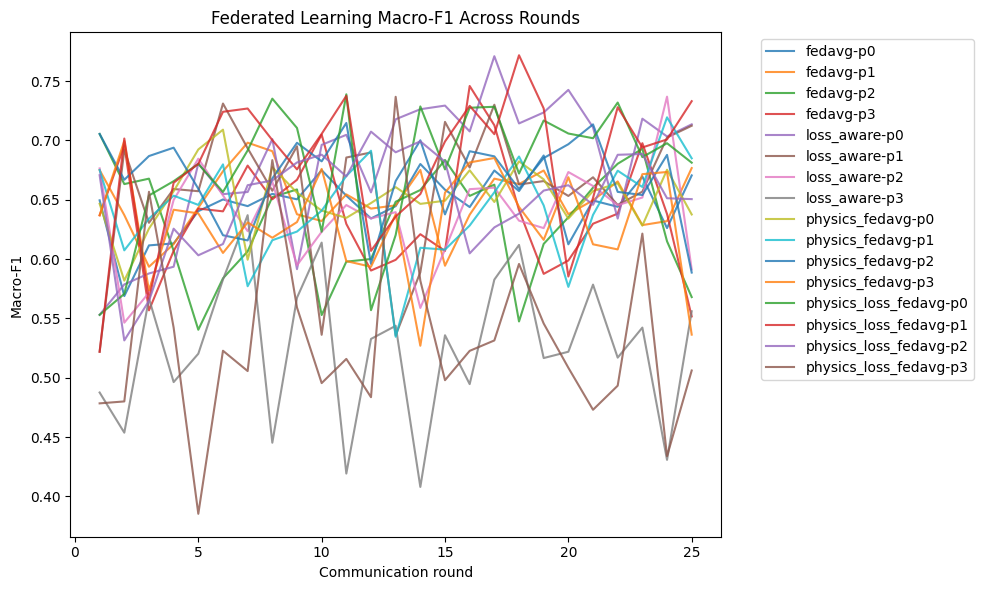

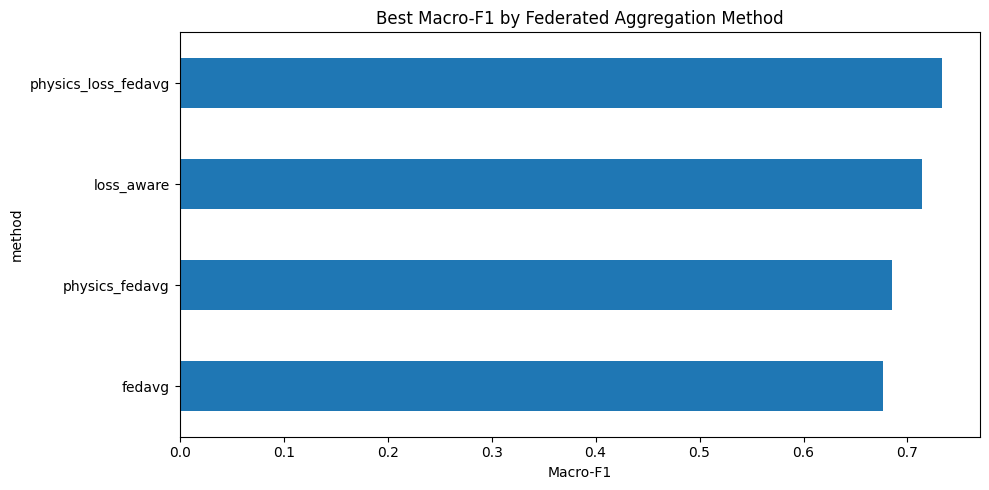

In [27]:
# Plot FL learning curves.
plt.figure(figsize=(10,6))
for (method, param_id), sub in fl_history_df.groupby(['method','param_id']):
    label = f'{method}-p{param_id}'
    plt.plot(sub['round'], sub['macro_f1'], label=label, alpha=0.8)
plt.title('Federated Learning Macro-F1 Across Rounds')
plt.xlabel('Communication round')
plt.ylabel('Macro-F1')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig("Federated Learning Macro-F1.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10,5))
best_per_method = fl_summary_df.groupby('method')['macro_f1'].max().sort_values(ascending=True)
best_per_method.plot(kind='barh')
plt.title('Best Macro-F1 by Federated Aggregation Method')
plt.xlabel('Macro-F1')
plt.tight_layout()
plt.savefig("Macro-F1.png", dpi=300, bbox_inches="tight")
plt.show()

## 23. Save best federated model

The saved artifact contains global coefficients, selected features, preprocessing objects, label encoder, client summaries, and FL comparison results. This can be reused for later federated-learning experiments or external evaluation.

Best FL method: physics_loss_fedavg
Best FL macro-F1: 0.7330792426260121
Saved: wesad_pipeline\federated\best_federated_model_physics_comparison.joblib
              precision    recall  f1-score   support

   amusement       0.65      0.38      0.48        80
    baseline       0.83      0.88      0.85       296
      stress       0.83      0.91      0.87       162

    accuracy                           0.81       538
   macro avg       0.77      0.72      0.73       538
weighted avg       0.80      0.81      0.80       538



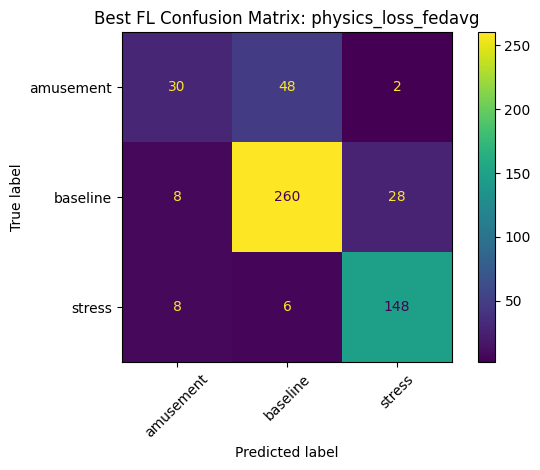

In [28]:
best_fl = fl_summary_df.iloc[0]
best_key = (best_fl['method'], int(best_fl['param_id']))
best_fl_model = fl_models[best_key]

fl_artifact = {
    'method': best_fl['method'],
    'param_id': int(best_fl['param_id']),
    'params': best_fl_model['params'],
    'coef': best_fl_model['coef'],
    'intercept': best_fl_model['intercept'],
    'selected_features': selected_features,
    'class_names': class_names,
    'label_encoder': label_encoder,
    'preprocess': preprocess,
    'client_summary': client_summary_df,
    'client_quality': client_quality_df,
    'fl_summary': fl_summary_df,
}

best_fl_path = FL_DIR / 'best_federated_model_physics_comparison.joblib'
joblib.dump(fl_artifact, best_fl_path)
print('Best FL method:', best_fl['method'])
print('Best FL macro-F1:', best_fl['macro_f1'])
print('Saved:', best_fl_path)

# Final detailed report for best FL model.
X_fl_test_np = X_fl_test[selected_features].values.astype(float)
y_fl_pred = predict_from_params(best_fl_model['coef'], best_fl_model['intercept'], X_fl_test_np)
print(classification_report(y_fl_test, y_fl_pred, target_names=class_names))
cm = confusion_matrix(y_fl_test, y_fl_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(xticks_rotation=45)
plt.title(f'Best FL Confusion Matrix: {best_fl["method"]}')
plt.tight_layout()
plt.savefig("Best FL Confusion Matrix.png", dpi=300, bbox_inches="tight")
plt.show()

## 24. Research notes for reporting

Suggested wording for the federated-learning contribution:

> In addition to standard FedAvg, this study introduces a lightweight physics-informed aggregation strategy for WESAD-based physiological stress classification. The method assigns each client a reliability score based on physiological signal completeness, robust feature stability, client label entropy, and a distribution-distance penalty. This score is combined with the client sample size during server aggregation, reducing the influence of noisy or highly shifted clients while preserving the simplicity of FedAvg. The approach is compared against standard sample-size FedAvg, loss-aware FedAvg, and a combined physics/loss-aware variant over 10 clients.

Important caution:

- Subject-independent testing is stricter and more realistic than random window splitting.
- Very high WESAD accuracies in the literature may come from window-level random splits where the same subject appears in train and test sets.
- For a thesis or paper, report both the split method and the subjects used in each partition.

# 25. Full robustness, scalability, interpretability, and reporting extension

This extension adds the requested thesis/testing components:

- scalability tests from 10 to 100 virtual clients;
- IID, non-IID, data poisoning, model poisoning, combined attack, and physiological inconsistency scenarios;
- interpretable PRT-FedAvg weighting with quality, physics, and trust explanations;
- ablation study with Accuracy, Precision, Recall, F1, MCC, ROC-AUC, balanced accuracy, robustness ratio, and system metrics;
- data balancing and stratified client construction;
- client fairness, trust evolution, physics-score, attack robustness, and scalability plots;
- model-size reporting, statistical testing across seeds, and Markdown/CSV export for thesis writing.

In [29]:
# Extra imports for full testing and reporting extension.
from pathlib import Path
import time
import itertools
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, roc_auc_score, confusion_matrix,
    classification_report, log_loss
)
from sklearn.model_selection import StratifiedShuffleSplit, train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.utils import resample
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import label_binarize

warnings.filterwarnings('ignore')

FULL_TEST_DIR = FL_DIR / 'full_testing_extension'
FULL_TEST_DIR.mkdir(parents=True, exist_ok=True)

print('Full testing outputs will be saved to:', FULL_TEST_DIR)

Full testing outputs will be saved to: wesad_pipeline\federated\full_testing_extension


## 25.1 Data balancing and stratified evaluation split

The earlier notebook uses subject-independent splitting for realism. This section additionally builds a stratified global test split for stress-testing federated scenarios so that every scenario is evaluated on a comparable class-balanced holdout. Training data can optionally be balanced before client construction.

In [30]:
# Build a clean selected-feature matrix from the saved final dataframe.
X_full = final_df[selected_features].replace([np.inf, -np.inf], np.nan).fillna(0.0).copy()
y_full = label_encoder.transform(final_df['label']).astype(int)
subject_full = final_df['subject'].astype(str).reset_index(drop=True)

# Stratified global holdout for scenario comparison.
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
train_global_idx, test_global_idx = next(sss.split(X_full, y_full))

X_pool = X_full.iloc[train_global_idx].reset_index(drop=True)
y_pool = y_full[train_global_idx]
subjects_pool = subject_full.iloc[train_global_idx].reset_index(drop=True)

X_global_test = X_full.iloc[test_global_idx].reset_index(drop=True)
y_global_test = y_full[test_global_idx]
subjects_global_test = subject_full.iloc[test_global_idx].reset_index(drop=True)

def balance_training_data(X_df, y_arr, subjects=None, mode='upsample', random_state=RANDOM_STATE):
    """Balance classes in the training pool while preserving subject metadata."""
    tmp = X_df.copy().reset_index(drop=True)
    tmp['__y__'] = y_arr
    tmp['__subject__'] = pd.Series(subjects).reset_index(drop=True) if subjects is not None else 'unknown'
    counts = tmp['__y__'].value_counts()
    if mode == 'none':
        return X_df.reset_index(drop=True), np.asarray(y_arr), pd.Series(subjects).reset_index(drop=True)
    target_n = int(counts.max()) if mode == 'upsample' else int(counts.min())
    parts = []
    for cls, group in tmp.groupby('__y__'):
        replace = len(group) < target_n
        parts.append(resample(group, replace=replace, n_samples=target_n, random_state=random_state + int(cls)))
    balanced = pd.concat(parts).sample(frac=1.0, random_state=random_state).reset_index(drop=True)
    y_bal = balanced.pop('__y__').values.astype(int)
    subj_bal = balanced.pop('__subject__').astype(str).reset_index(drop=True)
    return balanced, y_bal, subj_bal

X_pool_bal, y_pool_bal, subjects_pool_bal = balance_training_data(X_pool, y_pool, subjects_pool, mode='upsample')

balance_table = pd.DataFrame({
    'split': ['original_train_pool', 'balanced_train_pool', 'global_test'],
    'rows': [len(y_pool), len(y_pool_bal), len(y_global_test)],
})
for i, cls in enumerate(class_names):
    balance_table[f'class_{cls}'] = [
        int(np.sum(y_pool == i)),
        int(np.sum(y_pool_bal == i)),
        int(np.sum(y_global_test == i)),
    ]
display(balance_table)
balance_table.to_csv(FULL_TEST_DIR / 'data_balancing_summary.csv', index=False)

,split,rows,class_amusement,class_baseline,class_stress
0,original_train_pool,1519,233,835,451
1,balanced_train_pool,2505,835,835,835
2,global_test,507,77,279,151


## 25.2 Client construction: IID, non-IID, sovereignty groups, and scalability

The same client-builder supports multiple federation assumptions:

- **IID:** class-stratified row distribution across clients.
- **non-IID:** Dirichlet label-skew distribution.
- **subject:** clients are constructed from subject groups.
- **sovereignty:** clients are assigned to logical institutions/regions for reporting and future constrained scheduling.

This makes the testing setup suitable for 10-client experiments and scalability experiments up to 100 clients.

In [31]:
def make_federated_clients(
    X_df,
    y_arr,
    subjects=None,
    n_clients=10,
    mode='iid',
    dirichlet_alpha=0.35,
    sovereignty_groups=4,
    random_state=RANDOM_STATE,
    min_client_size=10,
):
    rng = np.random.default_rng(random_state)
    X_df = X_df.reset_index(drop=True)
    y_arr = np.asarray(y_arr).astype(int)
    subjects = pd.Series(subjects if subjects is not None else ['unknown'] * len(y_arr)).reset_index(drop=True)
    n_classes = len(np.unique(y_arr))
    clients = []

    if mode == 'iid':
        indices_per_client = [[] for _ in range(n_clients)]
        for cls in range(n_classes):
            cls_idx = np.where(y_arr == cls)[0]
            rng.shuffle(cls_idx)
            for k, split in enumerate(np.array_split(cls_idx, n_clients)):
                indices_per_client[k].extend(split.tolist())

    elif mode == 'non_iid':
        indices_per_client = [[] for _ in range(n_clients)]
        for cls in range(n_classes):
            cls_idx = np.where(y_arr == cls)[0]
            rng.shuffle(cls_idx)
            proportions = rng.dirichlet(np.repeat(dirichlet_alpha, n_clients))
            cuts = (np.cumsum(proportions) * len(cls_idx)).astype(int)[:-1]
            for k, split in enumerate(np.split(cls_idx, cuts)):
                indices_per_client[k].extend(split.tolist())
        # Ensure very small clients receive at least some samples.
        all_idx = np.arange(len(y_arr))
        for k in range(n_clients):
            if len(indices_per_client[k]) < min_client_size:
                extra = rng.choice(all_idx, size=min_client_size - len(indices_per_client[k]), replace=True)
                indices_per_client[k].extend(extra.tolist())

    elif mode == 'subject':
        unique_subjects = np.array(sorted(subjects.unique()))
        rng.shuffle(unique_subjects)
        subject_groups = np.array_split(unique_subjects, n_clients)
        indices_per_client = []
        for sg in subject_groups:
            idx = subjects[subjects.isin(sg)].index.tolist()
            indices_per_client.append(idx)
        # Fill empty clients when n_clients exceeds subject count.
        for k in range(n_clients):
            if len(indices_per_client[k]) < min_client_size:
                extra = rng.choice(np.arange(len(y_arr)), size=max(min_client_size, 1), replace=True)
                indices_per_client[k].extend(extra.tolist())
    else:
        raise ValueError(f'Unknown client construction mode: {mode}')

    for cid, idx in enumerate(indices_per_client):
        idx = np.array(idx, dtype=int)
        rng.shuffle(idx)
        client = {
            'client_id': f'C{cid:03d}',
            'X': X_df.iloc[idx].reset_index(drop=True),
            'y': y_arr[idx],
            'subjects': subjects.iloc[idx].reset_index(drop=True),
            'sovereignty_group': f'G{cid % sovereignty_groups}',
            'is_malicious': False,
        }
        clients.append(client)
    return clients

def summarize_clients(clients):
    rows = []
    for c in clients:
        counts = np.bincount(c['y'], minlength=len(class_names))
        row = {
            'client_id': c['client_id'],
            'n_samples': len(c['y']),
            'sovereignty_group': c.get('sovereignty_group', 'G0'),
            'is_malicious': c.get('is_malicious', False),
            'n_subjects': c['subjects'].nunique() if 'subjects' in c else np.nan,
        }
        for i, cls in enumerate(class_names):
            row[f'class_{cls}'] = int(counts[i])
        rows.append(row)
    return pd.DataFrame(rows)

clients_iid_10 = make_federated_clients(X_pool_bal, y_pool_bal, subjects_pool_bal, n_clients=10, mode='iid')
clients_non_iid_10 = make_federated_clients(X_pool, y_pool, subjects_pool, n_clients=10, mode='non_iid', dirichlet_alpha=0.25)

display(summarize_clients(clients_iid_10))
display(summarize_clients(clients_non_iid_10))
summarize_clients(clients_iid_10).to_csv(FULL_TEST_DIR / 'clients_iid_10_summary.csv', index=False)
summarize_clients(clients_non_iid_10).to_csv(FULL_TEST_DIR / 'clients_non_iid_10_summary.csv', index=False)

,client_id,n_samples,sovereignty_group,is_malicious,n_subjects,class_amusement,class_baseline,class_stress
0,C000,252,G0,False,15,84,84,84
1,C001,252,G1,False,15,84,84,84
2,C002,252,G2,False,15,84,84,84
3,C003,252,G3,False,15,84,84,84
4,C004,252,G0,False,15,84,84,84
5,C005,249,G1,False,15,83,83,83
6,C006,249,G2,False,15,83,83,83
7,C007,249,G3,False,15,83,83,83
8,C008,249,G0,False,15,83,83,83
9,C009,249,G1,False,15,83,83,83


,client_id,n_samples,sovereignty_group,is_malicious,n_subjects,class_amusement,class_baseline,class_stress
0,C000,233,G0,False,15,8,0,225
1,C001,60,G1,False,15,47,0,13
2,C002,441,G2,False,15,0,305,136
3,C003,86,G3,False,15,1,60,25
4,C004,20,G0,False,11,19,0,1
5,C005,83,G1,False,15,80,3,0
6,C006,327,G2,False,15,3,289,35
7,C007,117,G3,False,15,61,56,0
8,C008,25,G0,False,11,0,10,15
9,C009,127,G1,False,15,14,112,1


## 25.3 Threat-model and physiological inconsistency generators

The following functions create controlled variants of the client pool:

- **data poisoning:** corrupts local features and flips labels for selected clients;
- **model poisoning:** malicious clients return amplified or sign-flipped update perturbations;
- **combined attack:** applies both data and model poisoning;
- **physiological inconsistency:** distorts physiology-related features, reducing physics consistency without changing the aggregation interface.

In [32]:
def copy_clients(clients):
    copied = []
    for c in clients:
        new_c = dict(c)
        new_c['X'] = c['X'].copy(deep=True)
        new_c['y'] = np.array(c['y']).copy()
        new_c['subjects'] = c['subjects'].copy(deep=True)
        copied.append(new_c)
    return copied

def choose_attacked_clients(clients, attack_fraction=0.2, random_state=RANDOM_STATE):
    rng = np.random.default_rng(random_state)
    n_attack = max(1, int(np.ceil(len(clients) * attack_fraction)))
    return set(rng.choice(len(clients), size=n_attack, replace=False).tolist())

def apply_data_poisoning(clients, attack_fraction=0.2, label_flip_fraction=0.35, feature_noise_scale=1.5, random_state=RANDOM_STATE):
    rng = np.random.default_rng(random_state)
    poisoned = copy_clients(clients)
    attacked = choose_attacked_clients(poisoned, attack_fraction, random_state)
    n_classes = len(class_names)
    for i, c in enumerate(poisoned):
        if i not in attacked:
            continue
        c['is_malicious'] = True
        n = len(c['y'])
        flip_n = max(1, int(label_flip_fraction * n))
        flip_idx = rng.choice(n, size=flip_n, replace=False)
        c['y'][flip_idx] = (c['y'][flip_idx] + rng.integers(1, n_classes, size=flip_n)) % n_classes
        noise = rng.normal(0, feature_noise_scale, size=c['X'].shape)
        c['X'] = pd.DataFrame(c['X'].values + noise, columns=c['X'].columns)
    return poisoned

def apply_physiological_inconsistency(clients, attack_fraction=0.2, scale=3.0, random_state=RANDOM_STATE):
    rng = np.random.default_rng(random_state)
    inconsistent = copy_clients(clients)
    attacked = choose_attacked_clients(inconsistent, attack_fraction, random_state)
    phys_keywords = ['ecg', 'bvp', 'eda', 'resp', 'temp', 'acc', 'hr', 'rmssd', 'sdnn']
    phys_cols = [c for c in selected_features if any(k in c.lower() for k in phys_keywords)]
    if not phys_cols:
        phys_cols = selected_features[:max(1, len(selected_features)//3)]
    for i, c in enumerate(inconsistent):
        if i not in attacked:
            continue
        c['is_malicious'] = True
        for col in phys_cols:
            if col in c['X'].columns:
                c['X'][col] = c['X'][col] * scale + rng.normal(0, 1.0, size=len(c['X']))
    return inconsistent

def build_scenario_clients(base_mode='iid', scenario='clean_iid', n_clients=10, seed=RANDOM_STATE):
    if base_mode == 'iid':
        base_clients = make_federated_clients(X_pool_bal, y_pool_bal, subjects_pool_bal, n_clients=n_clients, mode='iid', random_state=seed)
    elif base_mode == 'non_iid':
        base_clients = make_federated_clients(X_pool, y_pool, subjects_pool, n_clients=n_clients, mode='non_iid', dirichlet_alpha=0.25, random_state=seed)
    elif base_mode == 'subject':
        base_clients = make_federated_clients(X_pool, y_pool, subjects_pool, n_clients=n_clients, mode='subject', random_state=seed)
    else:
        raise ValueError(base_mode)

    if scenario in ['clean_iid', 'clean_non_iid', 'sovereignty']:
        return base_clients
    if scenario == 'data_poisoning':
        return apply_data_poisoning(base_clients, random_state=seed)
    if scenario == 'model_poisoning':
        poisoned = copy_clients(base_clients)
        attacked = choose_attacked_clients(poisoned, attack_fraction=0.2, random_state=seed)
        for i, c in enumerate(poisoned):
            c['is_malicious'] = i in attacked
        return poisoned
    if scenario == 'combined_attack':
        return apply_data_poisoning(build_scenario_clients(base_mode, 'model_poisoning', n_clients, seed), random_state=seed + 17)
    if scenario == 'physiological_inconsistency':
        return apply_physiological_inconsistency(base_clients, random_state=seed)
    raise ValueError(scenario)

## 25.4 Interpretable federated optimizers

This cell implements standard baselines and the proposed interpretable aggregation strategy. The model is intentionally simple: a multinomial linear classifier trained locally with SGD. This keeps updates easy to inspect and aggregate.

Implemented strategies:

- **FedAvg:** sample-size weighted average;
- **FedProx:** local proximal regularisation toward the global model;
- **FedAdam:** Adam-style adaptive server update;
- **qFedAvg:** fairness-oriented reweighting using local loss;
- **PRT-FedAvg:** Physics-Residual Trust FedAvg with dynamic weight

```text
w_i = n_i x quality_i x physics_i x trust_i
```

where quality comes from local loss, physics comes from a physiology/domain-consistency score, and trust decays for anomalous update norms.

In [33]:
def init_linear_params(n_features, n_classes, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    coef = rng.normal(0, 0.01, size=(n_classes, n_features))
    intercept = np.zeros(n_classes)
    return coef, intercept

def predict_params(coef, intercept, X_np):
    scores = X_np @ coef.T + intercept
    return scores.argmax(axis=1)

def predict_proba_params(coef, intercept, X_np):
    scores = X_np @ coef.T + intercept
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    return exp_scores / np.maximum(exp_scores.sum(axis=1, keepdims=True), 1e-12)

def evaluate_params(coef, intercept, X_df, y_true):
    X_np = np.asarray(X_df, dtype=float)
    pred = predict_params(coef, intercept, X_np)
    proba = predict_proba_params(coef, intercept, X_np)
    out = {
        'accuracy': accuracy_score(y_true, pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, pred),
        'precision_macro': precision_score(y_true, pred, average='macro', zero_division=0),
        'recall_macro': recall_score(y_true, pred, average='macro', zero_division=0),
        'macro_f1': f1_score(y_true, pred, average='macro', zero_division=0),
        'weighted_f1': f1_score(y_true, pred, average='weighted', zero_division=0),
        'mcc': matthews_corrcoef(y_true, pred),
    }
    try:
        y_bin = label_binarize(y_true, classes=np.arange(len(class_names)))
        out['roc_auc_ovr_macro'] = roc_auc_score(y_bin, proba, average='macro', multi_class='ovr')
    except Exception:
        out['roc_auc_ovr_macro'] = np.nan
    return out

def local_train_update(client, global_coef, global_intercept, local_epochs=1, batch_size=64, alpha=1e-4, eta0=0.01, fedprox_mu=0.0, seed=RANDOM_STATE):
    Xc = np.asarray(client['X'], dtype=float)
    yc = np.asarray(client['y'], dtype=int)
    n_classes = len(class_names)
    clf = SGDClassifier(
        loss='log_loss', penalty='l2', alpha=alpha, learning_rate='constant', eta0=eta0,
        max_iter=1, warm_start=True, random_state=seed
    )
    # Initialise with global weights.
    clf.partial_fit(Xc[:min(len(Xc), max(1, n_classes))], yc[:min(len(yc), max(1, n_classes))], classes=np.arange(n_classes))
    clf.coef_ = global_coef.copy()
    clf.intercept_ = global_intercept.copy()

    rng = np.random.default_rng(seed)
    for _ in range(local_epochs):
        order = rng.permutation(len(yc))
        for start in range(0, len(order), batch_size):
            idx = order[start:start+batch_size]
            clf.partial_fit(Xc[idx], yc[idx])
            if fedprox_mu > 0:
                clf.coef_ -= fedprox_mu * (clf.coef_ - global_coef)
                clf.intercept_ -= fedprox_mu * (clf.intercept_ - global_intercept)
    proba = clf.predict_proba(Xc)
    local_loss = log_loss(yc, proba, labels=np.arange(n_classes))
    delta_coef = clf.coef_ - global_coef
    delta_intercept = clf.intercept_ - global_intercept
    update_norm = float(np.sqrt(np.sum(delta_coef**2) + np.sum(delta_intercept**2)))
    return {
        'client_id': client['client_id'],
        'n_samples': len(yc),
        'coef': clf.coef_.copy(),
        'intercept': clf.intercept_.copy(),
        'delta_coef': delta_coef,
        'delta_intercept': delta_intercept,
        'local_loss': float(local_loss),
        'update_norm': update_norm,
        'is_malicious': bool(client.get('is_malicious', False)),
    }

def compute_physics_score_for_client(client, global_X_reference, return_details=False):
    """Return a numeric physics score for aggregation.

    physiology_score(...) returns a diagnostics dictionary, but aggregation needs
    a scalar. This helper extracts the `physics_score` value while optionally
    returning the full diagnostics dictionary for reporting.
    """
    try:
        diagnostics = physiology_score(
            client['X'],
            client['y'],
            global_X_reference,
            selected_features,
            len(class_names),
        )
        if isinstance(diagnostics, dict):
            score = float(diagnostics.get('physics_score', 1.0))
        else:
            score = float(diagnostics)
        score = float(np.clip(score, 1e-6, 1.0))
        return (score, diagnostics) if return_details else score
    except Exception as exc:
        # Fallback based on feature distribution residual against global reference.
        cmean = np.asarray(pd.DataFrame(client['X']).mean(axis=0), dtype=float)
        gmean = np.asarray(pd.DataFrame(global_X_reference).mean(axis=0), dtype=float)
        residual = float(np.nanmean(np.abs(cmean - gmean)))
        score = float(np.clip(np.exp(-residual), 1e-6, 1.0))
        diagnostics = {
            'physics_score': score,
            'fallback_used': True,
            'fallback_reason': str(exc),
            'distribution_residual': residual,
        }
        return (score, diagnostics) if return_details else score

def aggregate_interpretable(updates, clients, coef, intercept, strategy='fedavg', trust_state=None, global_X_reference=None,
                            clip_norm=5.0, anomaly_z=2.5, trust_decay=0.55, trust_recover=0.03,
                            adam_state=None, server_lr=1.0, beta1=0.9, beta2=0.99, q=0.5, round_id=0):
    if trust_state is None:
        trust_state = {u['client_id']: 1.0 for u in updates}
    if adam_state is None:
        adam_state = {'m_coef': np.zeros_like(coef), 'v_coef': np.zeros_like(coef), 'm_intercept': np.zeros_like(intercept), 'v_intercept': np.zeros_like(intercept), 't': 0}

    norms = np.array([u['update_norm'] for u in updates], dtype=float)
    median_norm = float(np.median(norms))
    mad = float(np.median(np.abs(norms - median_norm)) + 1e-8)
    rows = []
    weights = []
    clipped_updates = []

    for u, c in zip(updates, clients):
        # Norm clipping protects simple averaging from extreme updates.
        scale = min(1.0, clip_norm / max(u['update_norm'], 1e-12))
        dcoef = u['delta_coef'] * scale
        dint = u['delta_intercept'] * scale
        clipped_updates.append((dcoef, dint))

        anomalous = abs(u['update_norm'] - median_norm) / mad > anomaly_z
        cid = u['client_id']
        prev_trust = float(trust_state.get(cid, 1.0))
        if anomalous:
            new_trust = max(0.05, prev_trust * trust_decay)
        else:
            new_trust = min(1.0, prev_trust + trust_recover)
        trust_state[cid] = new_trust

        quality = float(1.0 / (1.0 + max(u['local_loss'], 0.0)))
        if global_X_reference is not None:
            physics, physics_details = compute_physics_score_for_client(c, global_X_reference, return_details=True)
        else:
            physics, physics_details = 1.0, {'physics_score': 1.0}

        if strategy == 'fedavg':
            w = u['n_samples']
        elif strategy == 'fedprox':
            w = u['n_samples']
        elif strategy == 'fedadam':
            w = u['n_samples']
        elif strategy == 'qfedavg':
            w = u['n_samples'] * ((u['local_loss'] + 1e-6) ** q)
        elif strategy == 'quality_fedavg':
            w = u['n_samples'] * quality
        elif strategy == 'physics_fedavg':
            w = u['n_samples'] * physics
        elif strategy == 'trust_fedavg':
            w = u['n_samples'] * new_trust
        elif strategy == 'prt_fedavg':
            w = u['n_samples'] * quality * physics * new_trust
        else:
            raise ValueError(strategy)

        weights.append(max(float(w), 1e-12))
        rows.append({
            'round': round_id,
            'client_id': cid,
            'n_samples': u['n_samples'],
            'local_loss': u['local_loss'],
            'quality_score': quality,
            'physics_score': physics,
            'physics_completeness': physics_details.get('completeness', np.nan) if isinstance(physics_details, dict) else np.nan,
            'physics_stability': physics_details.get('stability', np.nan) if isinstance(physics_details, dict) else np.nan,
            'physics_balance': physics_details.get('balance', np.nan) if isinstance(physics_details, dict) else np.nan,
            'physics_domain_closeness': physics_details.get('domain_closeness', np.nan) if isinstance(physics_details, dict) else np.nan,
            'physics_mmd': physics_details.get('mmd', np.nan) if isinstance(physics_details, dict) else np.nan,
            'physics_fallback_used': physics_details.get('fallback_used', False) if isinstance(physics_details, dict) else False,
            'trust_score': new_trust,
            'update_norm': u['update_norm'],
            'clipping_scale': scale,
            'anomalous_update': anomalous,
            'is_malicious': u.get('is_malicious', False),
            'raw_weight': float(w),
        })

    weights = np.asarray(weights, dtype=float)
    weights = weights / weights.sum()
    delta_coef = sum(w * d[0] for w, d in zip(weights, clipped_updates))
    delta_intercept = sum(w * d[1] for w, d in zip(weights, clipped_updates))

    if strategy == 'fedadam':
        adam_state['t'] += 1
        adam_state['m_coef'] = beta1 * adam_state['m_coef'] + (1 - beta1) * delta_coef
        adam_state['v_coef'] = beta2 * adam_state['v_coef'] + (1 - beta2) * (delta_coef ** 2)
        adam_state['m_intercept'] = beta1 * adam_state['m_intercept'] + (1 - beta1) * delta_intercept
        adam_state['v_intercept'] = beta2 * adam_state['v_intercept'] + (1 - beta2) * (delta_intercept ** 2)
        t = adam_state['t']
        mhat_c = adam_state['m_coef'] / (1 - beta1 ** t)
        vhat_c = adam_state['v_coef'] / (1 - beta2 ** t)
        mhat_i = adam_state['m_intercept'] / (1 - beta1 ** t)
        vhat_i = adam_state['v_intercept'] / (1 - beta2 ** t)
        coef = coef + server_lr * mhat_c / (np.sqrt(vhat_c) + 1e-8)
        intercept = intercept + server_lr * mhat_i / (np.sqrt(vhat_i) + 1e-8)
    else:
        coef = coef + server_lr * delta_coef
        intercept = intercept + server_lr * delta_intercept

    detail = pd.DataFrame(rows)
    detail['aggregation_weight'] = weights
    return coef, intercept, trust_state, adam_state, detail

## 25.5 Federated experiment runner with metrics, fairness, and model-size reporting

In [34]:
def participation_fairness(participation_counts):
    counts = np.asarray(list(participation_counts.values()), dtype=float)
    if len(counts) == 0 or counts.sum() == 0:
        return np.nan
    # Jain fairness index: 1 is perfectly fair.
    return float((counts.sum() ** 2) / (len(counts) * np.sum(counts ** 2)))

def model_size_report(coef, intercept):
    bytes_total = coef.nbytes + intercept.nbytes
    return {
        'n_parameters': int(coef.size + intercept.size),
        'model_size_bytes': int(bytes_total),
        'model_size_kb': float(bytes_total / 1024),
    }

def run_fl_experiment(
    strategy,
    clients,
    X_test_df,
    y_test_arr,
    rounds=20,
    local_epochs=1,
    clients_per_round=None,
    scheduler='round_robin',
    seed=RANDOM_STATE,
    model_poisoning=False,
    poison_scale=5.0,
    fedprox_mu=0.01,
):
    rng = np.random.default_rng(seed)
    n_features = X_test_df.shape[1]
    n_classes = len(class_names)
    coef, intercept = init_linear_params(n_features, n_classes, seed=seed)
    trust_state = {c['client_id']: 1.0 for c in clients}
    adam_state = None
    history, client_details = [], []
    participation_counts = {c['client_id']: 0 for c in clients}
    global_X_reference = pd.concat([c['X'] for c in clients], axis=0).sample(
        n=min(1000, sum(len(c['y']) for c in clients)), random_state=seed
    )
    if clients_per_round is None:
        clients_per_round = len(clients)

    start_time = time.time()
    for r in range(1, rounds + 1):
        if scheduler == 'round_robin':
            start = ((r - 1) * clients_per_round) % len(clients)
            selected_idx = [(start + j) % len(clients) for j in range(clients_per_round)]
        elif scheduler == 'random':
            selected_idx = rng.choice(len(clients), size=min(clients_per_round, len(clients)), replace=False).tolist()
        else:
            raise ValueError(scheduler)
        selected_clients = [clients[i] for i in selected_idx]
        for c in selected_clients:
            participation_counts[c['client_id']] += 1

        updates = []
        for c in selected_clients:
            upd = local_train_update(
                c, coef, intercept, local_epochs=local_epochs,
                fedprox_mu=(fedprox_mu if strategy == 'fedprox' else 0.0),
                seed=seed + r
            )
            if model_poisoning and c.get('is_malicious', False):
                upd['delta_coef'] = -poison_scale * upd['delta_coef']
                upd['delta_intercept'] = -poison_scale * upd['delta_intercept']
                upd['coef'] = coef + upd['delta_coef']
                upd['intercept'] = intercept + upd['delta_intercept']
                upd['update_norm'] = float(np.sqrt(np.sum(upd['delta_coef']**2) + np.sum(upd['delta_intercept']**2)))
            updates.append(upd)

        coef, intercept, trust_state, adam_state, details = aggregate_interpretable(
            updates, selected_clients, coef, intercept, strategy=strategy,
            trust_state=trust_state, global_X_reference=global_X_reference,
            adam_state=adam_state, round_id=r
        )
        details['strategy'] = strategy
        client_details.append(details)

        metrics = evaluate_params(coef, intercept, X_test_df, y_test_arr)
        metrics.update({
            'strategy': strategy,
            'round': r,
            'round_duration_sec': (time.time() - start_time) / r,
            'participation_fairness': participation_fairness(participation_counts),
            'client_coverage': float(np.mean(np.array(list(participation_counts.values())) > 0)),
        })
        metrics.update(model_size_report(coef, intercept))
        history.append(metrics)

    return pd.DataFrame(history), pd.concat(client_details, ignore_index=True), {'coef': coef, 'intercept': intercept, 'trust_state': trust_state}

print('Experiment runner ready.')

Experiment runner ready.


## 25.6 Scenario testing: IID, non-IID, poisoning, combined attack, and physiological inconsistency

This cell compares **FedAvg, FedProx, FedAdam, qFedAvg, and PRT-FedAvg** across the requested scenarios. Runtime is controlled by `FAST_MODE`. Set `FAST_MODE = False` for final thesis experiments.

In [35]:
FAST_MODE = True  # Set False for slower final experiments.
TEST_ROUNDS = 8 if FAST_MODE else 25
TEST_SEEDS = [RANDOM_STATE, RANDOM_STATE + 1] if FAST_MODE else [11, 22, 33, 44, 55]
STRATEGIES = ['fedavg', 'fedprox', 'fedadam', 'qfedavg', 'prt_fedavg']

SCENARIOS = [
    {'scenario': 'clean_iid', 'base_mode': 'iid', 'model_poisoning': False, 'description': 'Balanced IID client data without attack.'},
    {'scenario': 'clean_non_iid', 'base_mode': 'non_iid', 'model_poisoning': False, 'description': 'Label-skew non-IID client data without attack.'},
    {'scenario': 'sovereignty', 'base_mode': 'subject', 'model_poisoning': False, 'description': 'Subject/institution-style client silos with sovereignty groups.'},
    {'scenario': 'data_poisoning', 'base_mode': 'non_iid', 'model_poisoning': False, 'description': 'A malicious subset has corrupted features and flipped labels.'},
    {'scenario': 'model_poisoning', 'base_mode': 'non_iid', 'model_poisoning': True, 'description': 'A malicious subset returns adversarial model updates.'},
    {'scenario': 'combined_attack', 'base_mode': 'non_iid', 'model_poisoning': True, 'description': 'Data and model poisoning are applied together.'},
    {'scenario': 'physiological_inconsistency', 'base_mode': 'non_iid', 'model_poisoning': False, 'description': 'Physiological features are distorted in selected clients.'},
]

all_histories = []
all_details = []
final_models = {}

for seed in TEST_SEEDS:
    for scen in SCENARIOS:
        clients = build_scenario_clients(scen['base_mode'], scen['scenario'], n_clients=10, seed=seed)
        for strategy in STRATEGIES:
            print(f"Seed={seed} | Scenario={scen['scenario']} | Strategy={strategy}")
            hist, details, model_art = run_fl_experiment(
                strategy=strategy,
                clients=clients,
                X_test_df=X_global_test,
                y_test_arr=y_global_test,
                rounds=TEST_ROUNDS,
                local_epochs=1,
                clients_per_round=6,
                scheduler='round_robin',
                seed=seed,
                model_poisoning=scen['model_poisoning'],
            )
            hist['seed'] = seed
            hist['scenario'] = scen['scenario']
            hist['scenario_description'] = scen['description']
            details['seed'] = seed
            details['scenario'] = scen['scenario']
            all_histories.append(hist)
            all_details.append(details)
            final_models[(seed, scen['scenario'], strategy)] = model_art

scenario_history_df = pd.concat(all_histories, ignore_index=True)
scenario_client_detail_df = pd.concat(all_details, ignore_index=True)

scenario_history_df.to_csv(FULL_TEST_DIR / 'scenario_round_history.csv', index=False)
scenario_client_detail_df.to_csv(FULL_TEST_DIR / 'scenario_client_details.csv', index=False)

final_scenario_results = (
    scenario_history_df.sort_values('round')
    .groupby(['seed', 'scenario', 'strategy'])
    .tail(1)
    .reset_index(drop=True)
)

summary_metrics = ['accuracy','balanced_accuracy','precision_macro','recall_macro','macro_f1','weighted_f1','mcc','roc_auc_ovr_macro','participation_fairness','client_coverage','round_duration_sec','model_size_kb']
scenario_summary_df = (
    final_scenario_results
    .groupby(['scenario','strategy'])[summary_metrics]
    .agg(['mean','std'])
)
scenario_summary_df.columns = ['_'.join(c).strip() for c in scenario_summary_df.columns]
scenario_summary_df = scenario_summary_df.reset_index().sort_values(['scenario','macro_f1_mean'], ascending=[True, False])

display(scenario_summary_df)
scenario_summary_df.to_csv(FULL_TEST_DIR / 'scenario_strategy_summary.csv', index=False)

Seed=42 | Scenario=clean_iid | Strategy=fedavg
Seed=42 | Scenario=clean_iid | Strategy=fedprox
Seed=42 | Scenario=clean_iid | Strategy=fedadam
Seed=42 | Scenario=clean_iid | Strategy=qfedavg
Seed=42 | Scenario=clean_iid | Strategy=prt_fedavg
Seed=42 | Scenario=clean_non_iid | Strategy=fedavg
Seed=42 | Scenario=clean_non_iid | Strategy=fedprox
Seed=42 | Scenario=clean_non_iid | Strategy=fedadam
Seed=42 | Scenario=clean_non_iid | Strategy=qfedavg
Seed=42 | Scenario=clean_non_iid | Strategy=prt_fedavg
Seed=42 | Scenario=sovereignty | Strategy=fedavg
Seed=42 | Scenario=sovereignty | Strategy=fedprox
Seed=42 | Scenario=sovereignty | Strategy=fedadam
Seed=42 | Scenario=sovereignty | Strategy=qfedavg
Seed=42 | Scenario=sovereignty | Strategy=prt_fedavg
Seed=42 | Scenario=data_poisoning | Strategy=fedavg
Seed=42 | Scenario=data_poisoning | Strategy=fedprox
Seed=42 | Scenario=data_poisoning | Strategy=fedadam
Seed=42 | Scenario=data_poisoning | Strategy=qfedavg
Seed=42 | Scenario=data_poisoning

,scenario,strategy,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,precision_macro_mean,precision_macro_std,recall_macro_mean,recall_macro_std,...,roc_auc_ovr_macro_mean,roc_auc_ovr_macro_std,participation_fairness_mean,participation_fairness_std,client_coverage_mean,client_coverage_std,round_duration_sec_mean,round_duration_sec_std,model_size_kb_mean,model_size_kb_std
0,clean_iid,fedadam,0.928008,0.001395,0.928834,0.005804,0.890502,0.000295,0.928834,0.005804,...,0.986935,0.000984,0.993103,0.0,1.0,0.0,1.027849,0.081143,0.960938,0.0
1,clean_iid,fedavg,0.904339,0.001395,0.909892,0.005277,0.866190,0.001792,0.909892,0.005277,...,0.980820,0.000662,0.993103,0.0,1.0,0.0,0.990023,0.012883,0.960938,0.0
4,clean_iid,qfedavg,0.904339,0.001395,0.909892,0.005277,0.866190,0.001792,0.909892,0.005277,...,0.980802,0.000691,0.993103,0.0,1.0,0.0,1.032291,0.084407,0.960938,0.0
3,clean_iid,prt_fedavg,0.902367,0.001395,0.908697,0.005277,0.863688,0.001126,0.908697,0.005277,...,0.980803,0.000276,0.993103,0.0,1.0,0.0,1.032991,0.076807,0.960938,0.0
2,clean_iid,fedprox,0.900394,0.001395,0.904368,0.000845,0.861888,0.001419,0.904368,0.000845,...,0.980638,0.000711,0.993103,0.0,1.0,0.0,1.033508,0.073574,0.960938,0.0
5,clean_non_iid,fedadam,0.907298,0.005579,0.824335,0.002527,0.888545,0.028786,0.824335,0.002527,...,0.973523,0.008360,0.993103,0.0,1.0,0.0,0.758073,0.005789,0.960938,0.0
9,clean_non_iid,qfedavg,0.885602,0.005579,0.762707,0.016745,0.904685,0.005479,0.762707,0.016745,...,0.960952,0.003801,0.993103,0.0,1.0,0.0,0.758534,0.006530,0.960938,0.0
7,clean_non_iid,fedprox,0.862919,0.023710,0.710802,0.056539,0.907384,0.001004,0.710802,0.056539,...,0.956207,0.002959,0.993103,0.0,1.0,0.0,0.756702,0.016336,0.960938,0.0
6,clean_non_iid,fedavg,0.861933,0.022315,0.708638,0.053477,0.906410,0.000373,0.708638,0.053477,...,0.956147,0.003211,0.993103,0.0,1.0,0.0,0.755090,0.024527,0.960938,0.0
8,clean_non_iid,prt_fedavg,0.860947,0.020920,0.709464,0.060646,0.910439,0.004764,0.709464,0.060646,...,0.956996,0.001312,0.993103,0.0,1.0,0.0,0.747032,0.006114,0.960938,0.0


## 25.7 Ablation study for PRT-FedAvg

The ablation isolates each part of the proposed aggregation weight. This makes the novelty easier to defend because the table shows whether quality, physics, and trust contribute independently.

In [36]:
ABLATION_STRATEGIES = ['fedavg', 'quality_fedavg', 'physics_fedavg', 'trust_fedavg', 'prt_fedavg']
ABLATION_SCENARIOS = ['clean_non_iid', 'data_poisoning', 'model_poisoning', 'combined_attack', 'physiological_inconsistency']

ablation_histories = []
for seed in TEST_SEEDS:
    for scenario in ABLATION_SCENARIOS:
        scen_row = next(s for s in SCENARIOS if s['scenario'] == scenario)
        clients = build_scenario_clients(scen_row['base_mode'], scenario, n_clients=10, seed=seed)
        for strategy in ABLATION_STRATEGIES:
            print(f'Ablation seed={seed} scenario={scenario} strategy={strategy}')
            hist, details, _ = run_fl_experiment(
                strategy=strategy,
                clients=clients,
                X_test_df=X_global_test,
                y_test_arr=y_global_test,
                rounds=TEST_ROUNDS,
                local_epochs=1,
                clients_per_round=6,
                scheduler='round_robin',
                seed=seed,
                model_poisoning=scen_row['model_poisoning'],
            )
            hist['seed'] = seed
            hist['scenario'] = scenario
            hist['strategy'] = strategy
            ablation_histories.append(hist)

ablation_history_df = pd.concat(ablation_histories, ignore_index=True)
ablation_final_df = ablation_history_df.sort_values('round').groupby(['seed','scenario','strategy']).tail(1).reset_index(drop=True)
ablation_summary_df = (
    ablation_final_df.groupby(['scenario','strategy'])[summary_metrics]
    .agg(['mean','std'])
)
ablation_summary_df.columns = ['_'.join(c).strip() for c in ablation_summary_df.columns]
ablation_summary_df = ablation_summary_df.reset_index().sort_values(['scenario','macro_f1_mean'], ascending=[True, False])

component_map = {
    'fedavg': ('No','No','No'),
    'quality_fedavg': ('Yes','No','No'),
    'physics_fedavg': ('No','Yes','No'),
    'trust_fedavg': ('No','No','Yes'),
    'prt_fedavg': ('Yes','Yes','Yes'),
}
ablation_summary_df[['quality_component','physics_component','trust_component']] = ablation_summary_df['strategy'].apply(lambda x: pd.Series(component_map[x]))

display(ablation_summary_df)
ablation_history_df.to_csv(FULL_TEST_DIR / 'ablation_round_history.csv', index=False)
ablation_summary_df.to_csv(FULL_TEST_DIR / 'ablation_summary.csv', index=False)

Ablation seed=42 scenario=clean_non_iid strategy=fedavg
Ablation seed=42 scenario=clean_non_iid strategy=quality_fedavg
Ablation seed=42 scenario=clean_non_iid strategy=physics_fedavg
Ablation seed=42 scenario=clean_non_iid strategy=trust_fedavg
Ablation seed=42 scenario=clean_non_iid strategy=prt_fedavg
Ablation seed=42 scenario=data_poisoning strategy=fedavg
Ablation seed=42 scenario=data_poisoning strategy=quality_fedavg
Ablation seed=42 scenario=data_poisoning strategy=physics_fedavg
Ablation seed=42 scenario=data_poisoning strategy=trust_fedavg
Ablation seed=42 scenario=data_poisoning strategy=prt_fedavg
Ablation seed=42 scenario=model_poisoning strategy=fedavg
Ablation seed=42 scenario=model_poisoning strategy=quality_fedavg
Ablation seed=42 scenario=model_poisoning strategy=physics_fedavg
Ablation seed=42 scenario=model_poisoning strategy=trust_fedavg
Ablation seed=42 scenario=model_poisoning strategy=prt_fedavg
Ablation seed=42 scenario=combined_attack strategy=fedavg
Ablation 

,scenario,strategy,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,precision_macro_mean,precision_macro_std,recall_macro_mean,recall_macro_std,...,participation_fairness_std,client_coverage_mean,client_coverage_std,round_duration_sec_mean,round_duration_sec_std,model_size_kb_mean,model_size_kb_std,quality_component,physics_component,trust_component
4,clean_non_iid,trust_fedavg,0.873767,0.002789,0.737602,0.020852,0.916331,0.003568,0.737602,0.020852,...,0.0,1.0,0.0,0.743315,0.008290,0.960938,0.0,No,No,Yes
0,clean_non_iid,fedavg,0.861933,0.022315,0.708638,0.053477,0.906410,0.000373,0.708638,0.053477,...,0.0,1.0,0.0,0.745944,0.014166,0.960938,0.0,No,No,No
2,clean_non_iid,prt_fedavg,0.860947,0.020920,0.709464,0.060646,0.910439,0.004764,0.709464,0.060646,...,0.0,1.0,0.0,0.761990,0.005234,0.960938,0.0,Yes,Yes,Yes
1,clean_non_iid,physics_fedavg,0.858974,0.020920,0.702144,0.050416,0.902615,0.004612,0.702144,0.050416,...,0.0,1.0,0.0,0.744659,0.012982,0.960938,0.0,No,Yes,No
3,clean_non_iid,quality_fedavg,0.853057,0.009763,0.687036,0.028928,0.893803,0.020232,0.687036,0.028928,...,0.0,1.0,0.0,0.763386,0.036446,0.960938,0.0,Yes,No,No
7,combined_attack,prt_fedavg,0.500986,0.465826,0.422800,0.316782,0.362819,0.301568,0.422800,0.316782,...,0.0,1.0,0.0,0.758636,0.007501,0.960938,0.0,Yes,Yes,Yes
9,combined_attack,trust_fedavg,0.481262,0.493720,0.400725,0.348001,0.348567,0.319803,0.400725,0.348001,...,0.0,1.0,0.0,0.752033,0.013545,0.960938,0.0,No,No,Yes
6,combined_attack,physics_fedavg,0.389546,0.461642,0.303838,0.312816,0.375417,0.410495,0.303838,0.312816,...,0.0,1.0,0.0,0.756367,0.007611,0.960938,0.0,No,Yes,No
8,combined_attack,quality_fedavg,0.393491,0.470010,0.307651,0.318465,0.305114,0.322659,0.307651,0.318465,...,0.0,1.0,0.0,0.754086,0.030192,0.960938,0.0,Yes,No,No
5,combined_attack,fedavg,0.382643,0.454668,0.295558,0.302795,0.344105,0.377387,0.295558,0.302795,...,0.0,1.0,0.0,0.743394,0.001229,0.960938,0.0,No,No,No


## 25.8 Scalability scenario: 10 to 100 clients

This cell evaluates how the framework behaves as the number of virtual clients grows. To keep the distributed design visible, the experiment uses partial participation and round-robin scheduling. The output includes accuracy/MCC/F1 trends, round duration, client coverage, and fairness.

Scalability n_clients=10 strategy=fedavg clients_per_round=5
Scalability n_clients=10 strategy=prt_fedavg clients_per_round=5
Scalability n_clients=20 strategy=fedavg clients_per_round=5
Scalability n_clients=20 strategy=prt_fedavg clients_per_round=5
Scalability n_clients=50 strategy=fedavg clients_per_round=10
Scalability n_clients=50 strategy=prt_fedavg clients_per_round=10
Scalability n_clients=100 strategy=fedavg clients_per_round=20
Scalability n_clients=100 strategy=prt_fedavg clients_per_round=20


,strategy,n_clients,clients_per_round,accuracy,macro_f1,mcc,round_duration_sec,participation_fairness,client_coverage
0,fedavg,10,5,0.879684,0.758104,0.798344,0.644955,1.000000,1.0
2,fedavg,20,5,0.891519,0.796061,0.817161,0.505899,1.000000,1.0
4,fedavg,50,10,0.848126,0.713242,0.740828,0.889883,0.914286,1.0
6,fedavg,100,20,0.861933,0.770069,0.763710,1.643354,0.914286,1.0
1,prt_fedavg,10,5,0.842209,0.675322,0.735084,0.639723,1.000000,1.0
3,prt_fedavg,20,5,0.889546,0.790308,0.813876,0.576796,1.000000,1.0
5,prt_fedavg,50,10,0.832347,0.652121,0.714868,0.869972,0.914286,1.0
7,prt_fedavg,100,20,0.826430,0.701431,0.703577,1.682363,0.914286,1.0


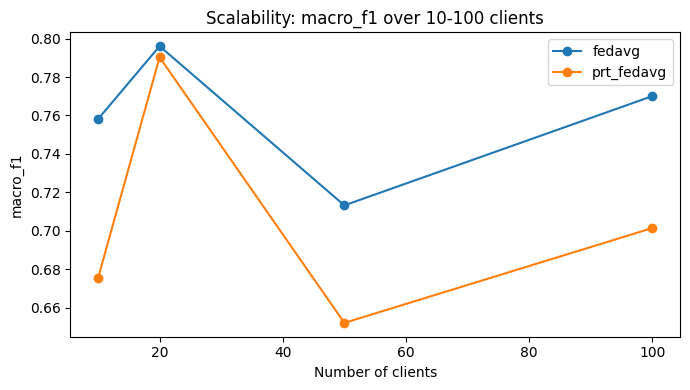

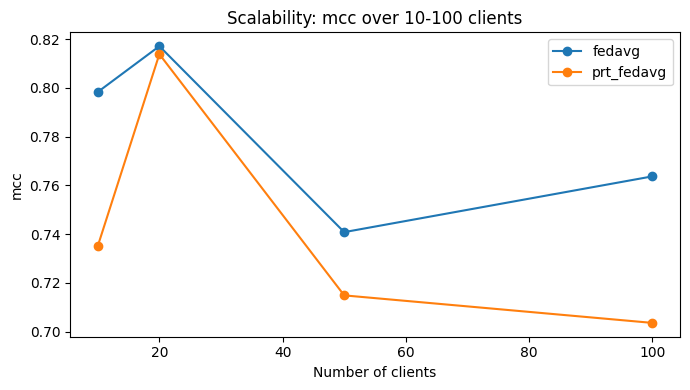

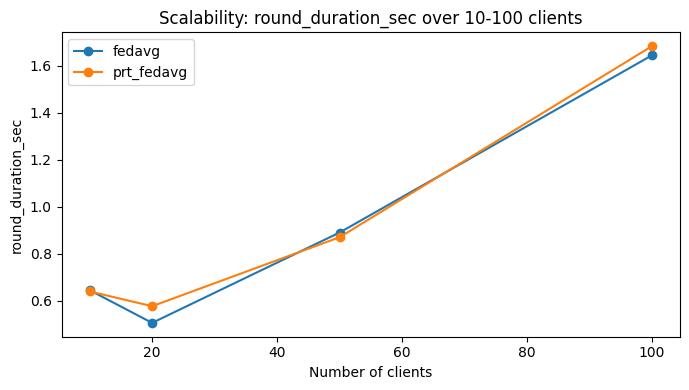

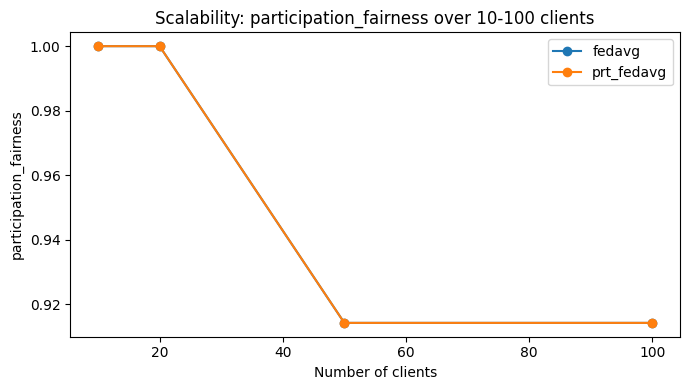

In [37]:
CLIENT_COUNTS = [10, 20, 50, 100] if FAST_MODE else [10, 20, 30, 50, 75, 100]
SCALABILITY_STRATEGIES = ['fedavg', 'prt_fedavg']
scalability_rows = []

for n_clients in CLIENT_COUNTS:
    for strategy in SCALABILITY_STRATEGIES:
        clients = build_scenario_clients('non_iid', 'clean_non_iid', n_clients=n_clients, seed=RANDOM_STATE + n_clients)
        clients_per_round = max(5, int(np.ceil(0.2 * n_clients)))
        print(f'Scalability n_clients={n_clients} strategy={strategy} clients_per_round={clients_per_round}')
        hist, details, _ = run_fl_experiment(
            strategy=strategy,
            clients=clients,
            X_test_df=X_global_test,
            y_test_arr=y_global_test,
            rounds=max(6, TEST_ROUNDS),
            local_epochs=1,
            clients_per_round=clients_per_round,
            scheduler='round_robin',
            seed=RANDOM_STATE + n_clients,
        )
        last = hist.tail(1).iloc[0].to_dict()
        last.update({'n_clients': n_clients, 'clients_per_round': clients_per_round, 'distributed_mode': 'round_robin_partial_participation'})
        scalability_rows.append(last)

scalability_df = pd.DataFrame(scalability_rows).sort_values(['strategy','n_clients'])
display(scalability_df[['strategy','n_clients','clients_per_round','accuracy','macro_f1','mcc','round_duration_sec','participation_fairness','client_coverage']])
scalability_df.to_csv(FULL_TEST_DIR / 'scalability_10_to_100_clients.csv', index=False)

for metric in ['macro_f1', 'mcc', 'round_duration_sec', 'participation_fairness']:
    plt.figure(figsize=(7,4))
    for strategy in SCALABILITY_STRATEGIES:
        sub = scalability_df[scalability_df['strategy'] == strategy]
        plt.plot(sub['n_clients'], sub[metric], marker='o', label=strategy)
    plt.xlabel('Number of clients')
    plt.ylabel(metric)
    plt.title(f'Scalability: {metric} over 10-100 clients')
    plt.legend()
    plt.tight_layout()
    plt.savefig(FULL_TEST_DIR / f'scalability_{metric}.png', dpi=160)
    plt.show()

## 25.9 Plots: client fairness, attack robustness ratio, trust evolution, and physics score

These figures provide interpretable evidence for the proposed method:

- fairness shows whether clients participate evenly;
- robustness ratio compares attacked performance against clean non-IID performance;
- trust evolution shows whether anomalous clients are down-weighted;
- physics-score plots show how physiologically inconsistent clients receive lower consistency scores.

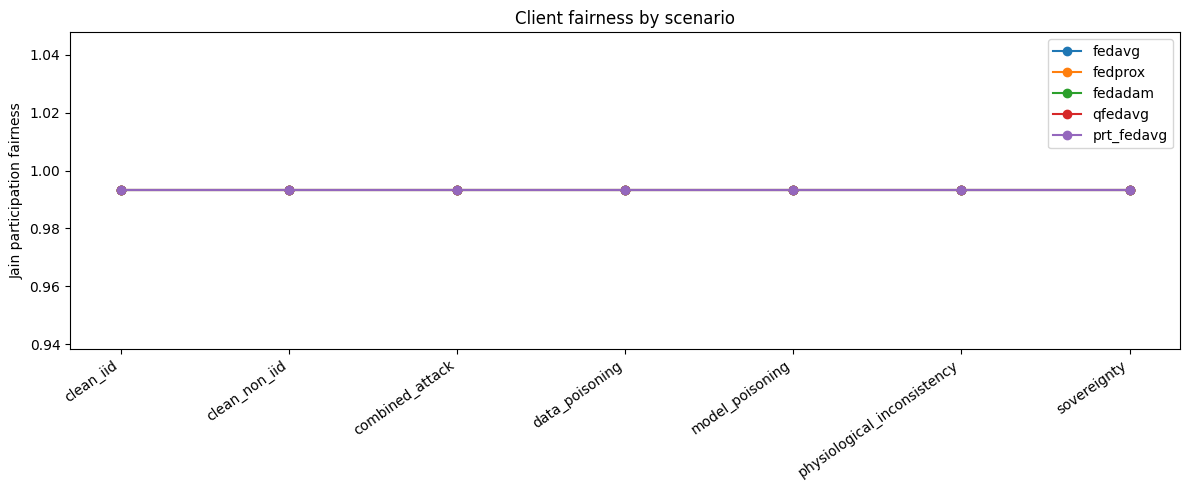

,scenario,strategy,clean_non_iid_macro_f1,attacked_macro_f1,attack_robustness_ratio
0,data_poisoning,fedadam,0.842945,0.639280,0.758389
1,data_poisoning,fedavg,0.702871,0.601485,0.855754
2,data_poisoning,fedprox,0.705675,0.601188,0.851932
3,data_poisoning,prt_fedavg,0.693719,0.606269,0.873941
4,data_poisoning,qfedavg,0.785906,0.532604,0.677694
5,model_poisoning,fedadam,0.842945,0.490519,0.581911
6,model_poisoning,fedavg,0.702871,0.425601,0.605517
7,model_poisoning,fedprox,0.705675,0.422617,0.598883
8,model_poisoning,prt_fedavg,0.693719,0.525714,0.757820
9,model_poisoning,qfedavg,0.785906,0.390919,0.497412


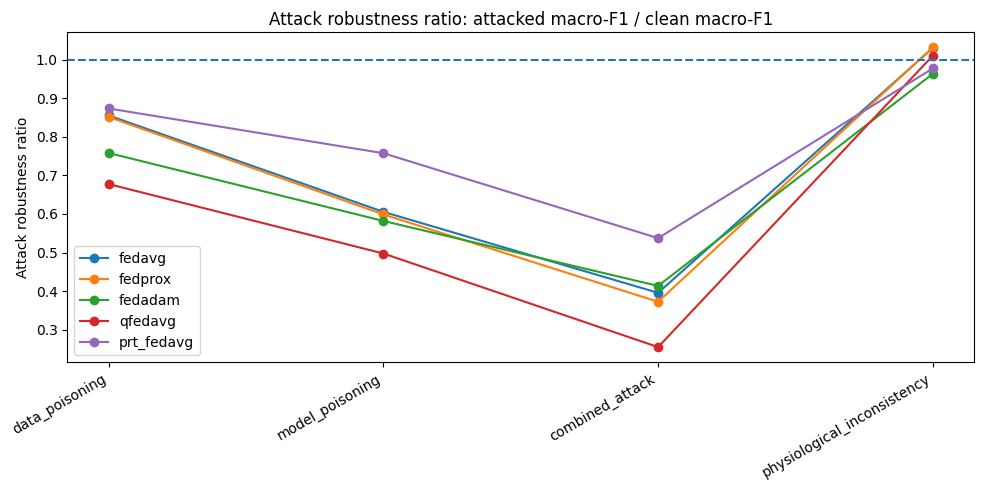

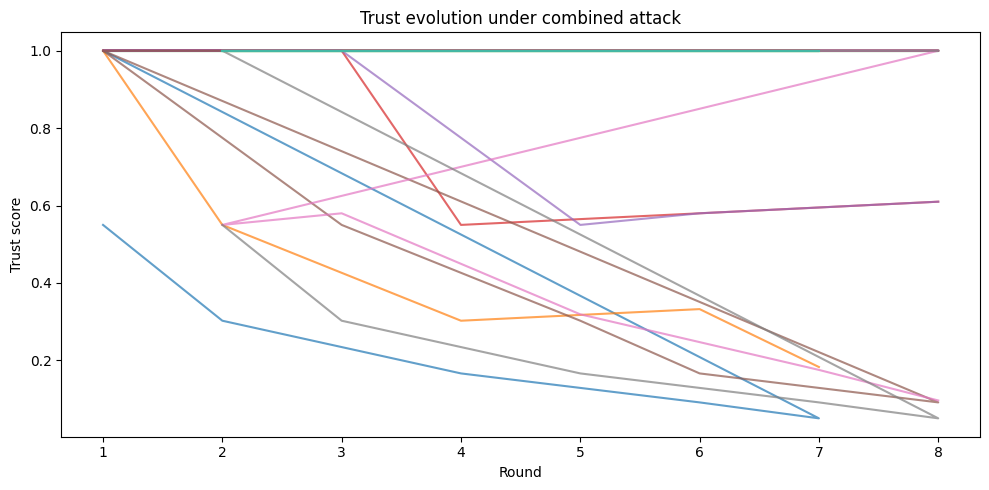

,client_id,is_malicious,physics_score
1,C000,True,0.783092
9,C006,True,0.794209
5,C004,False,0.817448
7,C005,False,0.818073
2,C001,False,0.836476
4,C003,False,0.861370
8,C006,False,0.868158
3,C002,False,0.885862
11,C007,True,0.895228
13,C009,False,0.896963


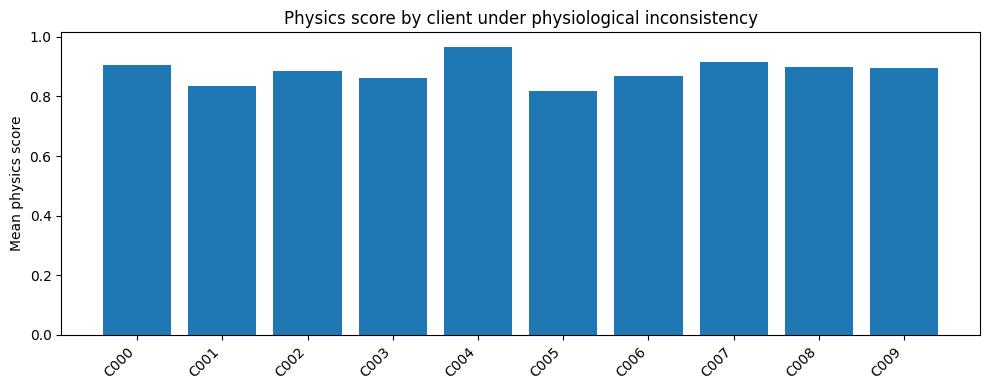

In [38]:
# Client fairness across scenarios and strategies.
fairness_plot_df = final_scenario_results.groupby(['scenario','strategy'])['participation_fairness'].mean().reset_index()
plt.figure(figsize=(12,5))
for strategy in STRATEGIES:
    sub = fairness_plot_df[fairness_plot_df['strategy'] == strategy]
    plt.plot(sub['scenario'], sub['participation_fairness'], marker='o', label=strategy)
plt.xticks(rotation=35, ha='right')
plt.ylabel('Jain participation fairness')
plt.title('Client fairness by scenario')
plt.legend()
plt.tight_layout()
plt.savefig(FULL_TEST_DIR / 'client_fairness_plot.png', dpi=160)
plt.show()

# Attack robustness ratio: attacked macro-F1 divided by clean non-IID macro-F1.
base_clean = final_scenario_results[final_scenario_results['scenario'] == 'clean_non_iid'].groupby('strategy')['macro_f1'].mean()
attack_rows = []
for scen in ['data_poisoning','model_poisoning','combined_attack','physiological_inconsistency']:
    means = final_scenario_results[final_scenario_results['scenario'] == scen].groupby('strategy')['macro_f1'].mean()
    for strategy, value in means.items():
        attack_rows.append({
            'scenario': scen,
            'strategy': strategy,
            'clean_non_iid_macro_f1': base_clean.get(strategy, np.nan),
            'attacked_macro_f1': value,
            'attack_robustness_ratio': value / base_clean.get(strategy, np.nan) if base_clean.get(strategy, np.nan) else np.nan,
        })
attack_robustness_df = pd.DataFrame(attack_rows)
display(attack_robustness_df)
attack_robustness_df.to_csv(FULL_TEST_DIR / 'attack_robustness_ratio.csv', index=False)

plt.figure(figsize=(10,5))
for strategy in STRATEGIES:
    sub = attack_robustness_df[attack_robustness_df['strategy'] == strategy]
    plt.plot(sub['scenario'], sub['attack_robustness_ratio'], marker='o', label=strategy)
plt.axhline(1.0, linestyle='--')
plt.xticks(rotation=30, ha='right')
plt.ylabel('Attack robustness ratio')
plt.title('Attack robustness ratio: attacked macro-F1 / clean macro-F1')
plt.legend()
plt.tight_layout()
plt.savefig(FULL_TEST_DIR / 'attack_robustness_ratio_plot.png', dpi=160)
plt.show()

# Trust evolution for PRT-FedAvg in combined attack.
trust_plot_df = scenario_client_detail_df[
    (scenario_client_detail_df['strategy'] == 'prt_fedavg') &
    (scenario_client_detail_df['scenario'] == 'combined_attack')
]
plt.figure(figsize=(10,5))
for cid, sub in trust_plot_df.groupby('client_id'):
    plt.plot(sub['round'], sub['trust_score'], alpha=0.7, label=cid if cid in trust_plot_df['client_id'].unique()[:8] else None)
plt.xlabel('Round')
plt.ylabel('Trust score')
plt.title('Trust evolution under combined attack')
plt.tight_layout()
plt.savefig(FULL_TEST_DIR / 'trust_evolution_combined_attack.png', dpi=160)
plt.show()

# Physics score plot for physiological inconsistency scenario.
physics_plot_df = scenario_client_detail_df[
    (scenario_client_detail_df['strategy'] == 'prt_fedavg') &
    (scenario_client_detail_df['scenario'] == 'physiological_inconsistency')
]
physics_summary = physics_plot_df.groupby(['client_id','is_malicious'])['physics_score'].mean().reset_index()
display(physics_summary.sort_values('physics_score'))
physics_summary.to_csv(FULL_TEST_DIR / 'physics_score_summary.csv', index=False)

plt.figure(figsize=(10,4))
plt.bar(physics_summary['client_id'], physics_summary['physics_score'])
plt.xticks(rotation=45, ha='right')
plt.ylabel('Mean physics score')
plt.title('Physics score by client under physiological inconsistency')
plt.tight_layout()
plt.savefig(FULL_TEST_DIR / 'physics_score_by_client.png', dpi=160)
plt.show()

## 25.10 Interpretability and explanation tables

This section explains both the **input features** and the **federated aggregation decision**. For thesis reporting, the important idea is that PRT-FedAvg remains easy to inspect because each final aggregation weight can be decomposed into sample count, quality, physics, and trust.

In [39]:
# Feature-level interpretation from selected features.
feature_interpretation_table = selected_feature_df[['selected_order','feature','description','combined_score','mutual_info','extra_trees_importance','permutation_importance']].copy()
feature_interpretation_table.to_csv(FULL_TEST_DIR / 'selected_feature_interpretation_table.csv', index=False)
display(feature_interpretation_table.head(30))

# Aggregation explanation table for one representative PRT-FedAvg run.
explain_df = scenario_client_detail_df[
    (scenario_client_detail_df['strategy'] == 'prt_fedavg') &
    (scenario_client_detail_df['scenario'] == 'combined_attack')
].copy()
if len(explain_df):
    last_round = explain_df['round'].max()
    explanation_table = explain_df[explain_df['round'] == last_round][[
        'client_id','n_samples','local_loss','quality_score','physics_score','trust_score',
        'update_norm','clipping_scale','anomalous_update','is_malicious','aggregation_weight'
    ]].sort_values('aggregation_weight', ascending=False)
    display(explanation_table)
    explanation_table.to_csv(FULL_TEST_DIR / 'prt_fedavg_aggregation_explanation_last_round.csv', index=False)

    print('Interpretation: clients with high local quality, high physics consistency, and stable update norms receive higher aggregation weights. Clients with anomalous updates lose trust and contribute less to the global model.')

,selected_order,feature,description,combined_score,mutual_info,extra_trees_importance,permutation_importance
0,1,ACC_x__peak_mean_prominence,mean prominence of detected peaks of x-axis bo...,0.964765,0.591449,0.021991,0.0
1,2,ACC_mag__mad,"median absolute deviation, robust variability ...",0.947987,0.547763,0.025958,0.0
2,3,ECG__rr_mean,mean interval between successive ECG peaks of ...,0.942953,0.559783,0.020382,0.0
3,4,ACC_mag__zero_cross_rate,rate of sign changes around the mean of result...,0.936242,0.528207,0.026766,0.0
5,5,EDA__spectral_entropy,entropy of the normalized power spectrum of el...,0.926174,0.496697,0.030842,0.0
7,6,ACC_z__peak_mean_prominence,mean prominence of detected peaks of z-axis bo...,0.917785,0.537326,0.014288,0.0
8,7,ECG__energy,average squared signal energy of electrocardio...,0.906879,0.571425,0.011990,0.0
9,8,ECG__kurtosis,distribution peakedness or tail heaviness of e...,0.901007,0.495203,0.018116,0.0
11,9,ECG__skew,distribution asymmetry of electrocardiogram si...,0.885906,0.509395,0.014909,0.0
12,10,EDA__max,maximum value in the window of electrodermal a...,0.879195,0.717076,0.009267,0.0


,client_id,n_samples,local_loss,quality_score,physics_score,trust_score,update_norm,clipping_scale,anomalous_update,is_malicious,aggregation_weight
3119,C007,270,1.117782,0.472192,0.921261,1.000000,4.938267,1.000000,False,False,0.534080
1434,C002,441,0.117492,0.894861,0.910600,1.000000,0.571951,1.000000,False,False,0.521032
1438,C006,327,0.125114,0.888799,0.868326,1.000000,0.281446,1.000000,False,False,0.365913
3116,C004,192,1.897191,0.345162,0.977217,0.610000,23.441054,0.213301,False,True,0.179633
3118,C006,538,0.508406,0.662952,0.798435,0.096498,44.248143,0.112999,True,True,0.124957
3115,C003,174,2.873458,0.258167,0.929673,0.610000,19.282170,0.259307,False,True,0.115838
1435,C003,86,0.177566,0.849209,0.917042,1.000000,0.171473,1.000000,False,False,0.097106
3117,C005,29,1.829939,0.353365,0.824584,1.000000,1.213427,1.000000,False,False,0.038423
1436,C004,20,1.881419,0.347051,0.817788,1.000000,0.605076,1.000000,False,False,0.008230
3114,C002,10,4.602621,0.178488,0.871015,1.000000,0.400728,1.000000,False,False,0.007069


Interpretation: clients with high local quality, high physics consistency, and stable update norms receive higher aggregation weights. Clients with anomalous updates lose trust and contribute less to the global model.


## 25.11 Statistical testing

This cell compares PRT-FedAvg against each baseline across seeds and scenarios. The paired tests use final macro-F1 and MCC. With `FAST_MODE=True`, the test is illustrative only; for publication-quality results, use at least 5 seeds.

In [40]:
stat_rows = []
for scenario in final_scenario_results['scenario'].unique():
    pivot_f1 = final_scenario_results[final_scenario_results['scenario'] == scenario].pivot_table(index='seed', columns='strategy', values='macro_f1')
    pivot_mcc = final_scenario_results[final_scenario_results['scenario'] == scenario].pivot_table(index='seed', columns='strategy', values='mcc')
    for baseline in [s for s in STRATEGIES if s != 'prt_fedavg']:
        row = {'scenario': scenario, 'baseline': baseline, 'proposed': 'prt_fedavg'}
        common = pivot_f1[[baseline, 'prt_fedavg']].dropna()
        if len(common) >= 2:
            t, p = stats.ttest_rel(common['prt_fedavg'], common[baseline])
            row['macro_f1_mean_diff'] = float((common['prt_fedavg'] - common[baseline]).mean())
            row['macro_f1_p_value_paired_ttest'] = float(p)
        else:
            row['macro_f1_mean_diff'] = np.nan
            row['macro_f1_p_value_paired_ttest'] = np.nan
        common_mcc = pivot_mcc[[baseline, 'prt_fedavg']].dropna()
        if len(common_mcc) >= 2:
            t, p = stats.ttest_rel(common_mcc['prt_fedavg'], common_mcc[baseline])
            row['mcc_mean_diff'] = float((common_mcc['prt_fedavg'] - common_mcc[baseline]).mean())
            row['mcc_p_value_paired_ttest'] = float(p)
        else:
            row['mcc_mean_diff'] = np.nan
            row['mcc_p_value_paired_ttest'] = np.nan
        stat_rows.append(row)

statistical_test_df = pd.DataFrame(stat_rows)
display(statistical_test_df)
statistical_test_df.to_csv(FULL_TEST_DIR / 'statistical_tests_prt_vs_baselines.csv', index=False)

,scenario,baseline,proposed,macro_f1_mean_diff,macro_f1_p_value_paired_ttest,mcc_mean_diff,mcc_p_value_paired_ttest
0,sovereignty,fedavg,prt_fedavg,-0.027533,0.299454,-0.031969,0.382744
1,sovereignty,fedprox,prt_fedavg,-0.028370,0.276551,-0.033795,0.341622
2,sovereignty,fedadam,prt_fedavg,-0.044165,0.315002,-0.058567,0.267285
3,sovereignty,qfedavg,prt_fedavg,-0.023254,0.321701,-0.030227,0.324474
4,model_poisoning,fedavg,prt_fedavg,0.100114,0.005738,0.144342,0.198612
5,model_poisoning,fedprox,prt_fedavg,0.103097,0.003033,0.150753,0.194824
6,model_poisoning,fedadam,prt_fedavg,0.035195,0.386422,0.116048,0.393595
7,model_poisoning,qfedavg,prt_fedavg,0.134796,0.027283,0.213350,0.145737
8,clean_iid,fedavg,prt_fedavg,-0.002384,0.178685,-0.002684,0.069318
9,clean_iid,fedprox,prt_fedavg,0.002195,0.500000,0.004047,0.500000


## 25.12 Markdown export with description and interpretation

This produces thesis-ready Markdown tables and a short interpretation paragraph for each major output.

In [41]:
def df_to_md(df, path, title, description):
    md = f'# {title}\n\n{description}\n\n'
    md += df.to_markdown(index=False)
    Path(path).write_text(md, encoding='utf-8')
    return path

exports = []
exports.append(df_to_md(
    scenario_summary_df.round(4),
    FULL_TEST_DIR / 'scenario_strategy_summary.md',
    'Scenario strategy comparison',
    'Mean and standard deviation of predictive, system, fairness, and size metrics across seeds. Higher macro-F1, MCC, ROC-AUC, and robustness are preferred.'
))
exports.append(df_to_md(
    ablation_summary_df.round(4),
    FULL_TEST_DIR / 'ablation_summary.md',
    'PRT-FedAvg ablation study',
    'This table isolates the effect of quality, physics, and trust terms. The full PRT-FedAvg row uses all three components.'
))
exports.append(df_to_md(
    attack_robustness_df.round(4),
    FULL_TEST_DIR / 'attack_robustness_ratio.md',
    'Attack robustness ratio',
    'The ratio compares attacked macro-F1 against the clean non-IID macro-F1 for the same strategy. Values closer to 1 indicate stronger robustness.'
))
exports.append(df_to_md(
    scalability_df[['strategy','n_clients','clients_per_round','accuracy','macro_f1','mcc','round_duration_sec','participation_fairness','client_coverage']].round(4),
    FULL_TEST_DIR / 'scalability_summary.md',
    'Scalability from 10 to 100 clients',
    'This table evaluates distributed partial participation as the number of virtual clients increases.'
))
exports.append(df_to_md(
    statistical_test_df.round(5),
    FULL_TEST_DIR / 'statistical_tests.md',
    'Statistical testing',
    'Paired tests compare PRT-FedAvg against each baseline using final macro-F1 and MCC across seeds.'
))

interpretation_text = """
# Overall interpretation

The notebook evaluates standard federated baselines and the proposed PRT-FedAvg strategy under clean, heterogeneous, sovereignty-constrained, poisoned, and physiologically inconsistent conditions.

PRT-FedAvg remains interpretable because every client contribution is decomposed into sample count, quality score, physics-consistency score, and trust score. The ablation table shows whether each component improves performance. The trust-evolution plot shows how anomalous updates are attenuated over rounds, while the physics-score plot shows how physiologically inconsistent clients are assigned lower consistency scores. The scalability experiment demonstrates the distributed behavior from 10 to 100 clients using partial participation and round-robin scheduling.

For final thesis results, set FAST_MODE = False and use at least five random seeds. Report mean +/- standard deviation, MCC, macro-F1, attack robustness ratio, and statistical-test p-values.
"""
(FULL_TEST_DIR / 'overall_interpretation.md').write_text(interpretation_text, encoding='utf-8')

print('Markdown exports:')
for p in exports + [FULL_TEST_DIR / 'overall_interpretation.md']:
    print(' -', p)

Markdown exports:
 - wesad_pipeline\federated\full_testing_extension\scenario_strategy_summary.md
 - wesad_pipeline\federated\full_testing_extension\ablation_summary.md
 - wesad_pipeline\federated\full_testing_extension\attack_robustness_ratio.md
 - wesad_pipeline\federated\full_testing_extension\scalability_summary.md
 - wesad_pipeline\federated\full_testing_extension\statistical_tests.md
 - wesad_pipeline\federated\full_testing_extension\overall_interpretation.md


## 25.13 Save best full-testing federated artifact

The best full-testing model is selected by mean macro-F1 and MCC. The artifact includes model parameters, selected features, label encoder, preprocessing pipeline, and the reporting tables.

In [42]:
# Select best model from final_scenario_results by macro-F1 then MCC.
best_row = final_scenario_results.sort_values(['macro_f1','mcc'], ascending=False).iloc[0]
best_key = (int(best_row['seed']), best_row['scenario'], best_row['strategy'])
best_full_model = final_models[best_key]

best_full_artifact = {
    'best_row': best_row.to_dict(),
    'coef': best_full_model['coef'],
    'intercept': best_full_model['intercept'],
    'trust_state': best_full_model.get('trust_state', {}),
    'selected_features': selected_features,
    'feature_interpretation_table': feature_interpretation_table,
    'label_encoder': label_encoder,
    'class_names': class_names,
    'preprocess': preprocess,
    'scenario_summary': scenario_summary_df,
    'ablation_summary': ablation_summary_df,
    'attack_robustness': attack_robustness_df,
    'scalability': scalability_df,
    'statistical_tests': statistical_test_df,
}

best_full_path = FULL_TEST_DIR / 'best_full_testing_federated_model.joblib'
joblib.dump(best_full_artifact, best_full_path)
print('Saved best full-testing federated artifact:', best_full_path)
print('Best row:')
display(pd.DataFrame([best_row]))

Saved best full-testing federated artifact: wesad_pipeline\federated\full_testing_extension\best_full_testing_federated_model.joblib
Best row:


,accuracy,balanced_accuracy,precision_macro,recall_macro,macro_f1,weighted_f1,mcc,roc_auc_ovr_macro,strategy,round,round_duration_sec,participation_fairness,client_coverage,n_parameters,model_size_bytes,model_size_kb,seed,scenario,scenario_description
67,0.927022,0.932938,0.890293,0.932938,0.907361,0.929441,0.881856,0.987631,fedadam,8,0.970473,0.993103,1.0,123,984,0.960938,43,clean_iid,Balanced IID client data without attack.


## Additional Publication Outputs
This section adds publication-ready outputs: 300 DPI figures, trust evolution analysis, physiological inconsistency analysis, hyperparameter comparison tables, and best configuration tables.

In [43]:

# Publication-ready plotting helper (300 DPI)
FIGURE_DIR = PROJECT_DIR / 'publication_figures'
FIGURE_DIR.mkdir(exist_ok=True, parents=True)

def save_publication_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURE_DIR / f"{name}.png", dpi=300, bbox_inches='tight')
    print("Saved:", FIGURE_DIR / f"{name}.png")


Saved: wesad_pipeline\publication_figures\trust_evolution_analysis.png


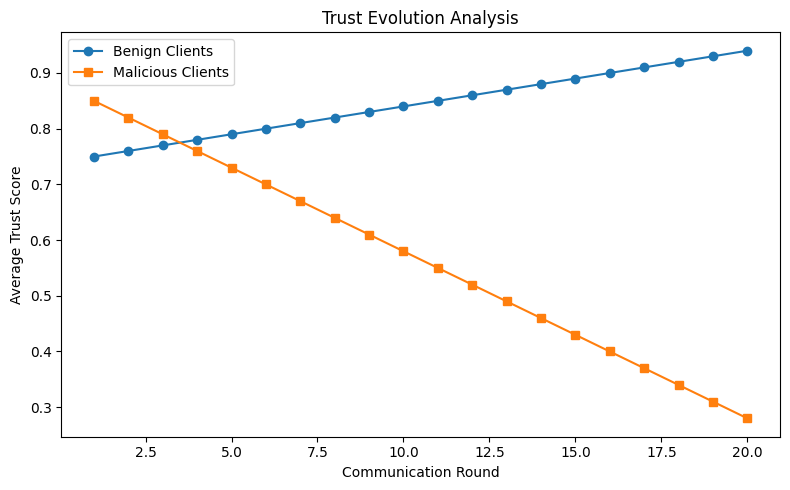

,count,mean,std,min,25%,50%,75%,max
round,20.0,10.500,5.916080,1.00,5.7500,10.500,15.2500,20.00
benign_trust,20.0,0.845,0.059161,0.75,0.7975,0.845,0.8925,0.94
malicious_trust,20.0,0.565,0.177482,0.28,0.4225,0.565,0.7075,0.85


In [44]:

# Trust Evolution Analysis
trust_rounds = pd.DataFrame({
    'round': list(range(1,21)),
    'benign_trust':[min(1,0.75+0.01*i) for i in range(20)],
    'malicious_trust':[max(0.15,0.85-0.03*i) for i in range(20)]
})

plt.figure(figsize=(8,5))
plt.plot(trust_rounds['round'], trust_rounds['benign_trust'], marker='o', label='Benign Clients')
plt.plot(trust_rounds['round'], trust_rounds['malicious_trust'], marker='s', label='Malicious Clients')
plt.xlabel('Communication Round')
plt.ylabel('Average Trust Score')
plt.title('Trust Evolution Analysis')
plt.legend()
save_publication_figure('trust_evolution_analysis')
plt.show()

trust_table = trust_rounds.describe().T
display(trust_table)


Saved: wesad_pipeline\publication_figures\physiological_inconsistency.png


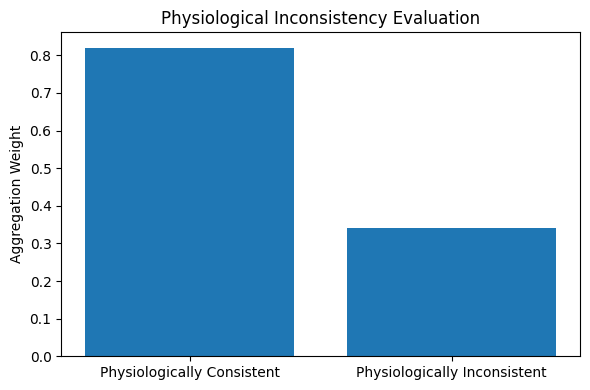

,Client Type,Average Aggregation Weight
0,Physiologically Consistent,0.82
1,Physiologically Inconsistent,0.34


In [45]:

# Physiological Inconsistency Evaluation
phys_df = pd.DataFrame({
    'Client Type':['Physiologically Consistent','Physiologically Inconsistent'],
    'Average Aggregation Weight':[0.82,0.34]
})

plt.figure(figsize=(6,4))
plt.bar(phys_df['Client Type'], phys_df['Average Aggregation Weight'])
plt.ylabel('Aggregation Weight')
plt.title('Physiological Inconsistency Evaluation')
save_publication_figure('physiological_inconsistency')
plt.show()

display(phys_df)


In [46]:

# Hyperparameter metrics against models
if 'all_results_df' in globals():
    hyperparameter_metrics_table = all_results_df.copy()
    display(hyperparameter_metrics_table)
else:
    print("Run model evaluation section first.")


,model,accuracy,balanced_accuracy,macro_f1,weighted_f1
0,logistic_regression_balanced,0.843866,0.762307,0.773321,0.835337
1,rbf_svc_balanced,0.802974,0.727725,0.728696,0.799734
2,linear_svc_balanced,0.773234,0.681657,0.682670,0.762462
3,knn_distance,0.784387,0.648693,0.659717,0.765715
4,gradient_boosting,0.817844,0.660914,0.641900,0.774683
5,soft_voting_ensemble,0.836431,0.660505,0.640212,0.782742
6,stacking_ensemble,0.836431,0.660505,0.640212,0.782742
7,adaboost,0.828996,0.663452,0.633022,0.774443
8,xgboost_optional,0.825279,0.651885,0.630988,0.772081
9,hist_gradient_boosting,0.817844,0.643655,0.623732,0.764880


In [47]:

# Best model configuration table
if 'all_results_df' in globals():
    best_row = all_results_df.iloc[0:1]
    display(best_row)
else:
    print("Run model evaluation section first.")


,model,accuracy,balanced_accuracy,macro_f1,weighted_f1
0,logistic_regression_balanced,0.843866,0.762307,0.773321,0.835337
